<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/FedVQC_IoTAnomalyDetection_Delhibabu2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Federated variational quantum circuits for IoT anomaly detection: Delhibabu, Mazzara and Distefano (2026) step by step

This notebook re-implements, runs and checks the method of

> Radhakrishnan Delhibabu, Manuel Mazzara and Salvatore Distefano, "Federated Variational Quantum Neural Networks for
> Privacy-Preserving Anomaly Detection in IoT", *2026 IEEE International Conference on Smart Computing Workshops and Other
> Affiliated events (SmartComp Companion)*, pp. 97-102, IEEE, 2026. DOI 10.1109/SMARTCOMP-Companion70724.2026.00033

The paper publishes no code. Everything below is written from its six-page description (Sections III-V, Algorithm 1, Tables III-IV).

**What the notebook does.** Ten simulated IoT edge nodes each hold a non-IID shard of the NSL-KDD network-intrusion data. Every
node runs the same small variational quantum circuit (8 qubits, angle encoding, 4 hardware-efficient layers, 64 rotation
angles) as a local anomaly detector and trains it with the **parameter-shift rule**. A parameter server averages the parameter
updates (Federated Quantum Averaging, "FedQA", Algorithm 1) for 50 communication rounds. The notebook then repeats the
experiment with the paper's depolarizing noise, compares against federated classical baselines and centralised
Random-Forest / RBF-SVM models on identical inputs, redraws the paper's convergence figure (Fig. 5), results table (Table IV) and
communication figure (Fig. 6), and ends with a side-by-side comparison with a verdict per claim.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first code cell
installs a pinned PennyLane (used for the circuit drawings and for cross-checking the simulator); if Colab asks you to restart
the session, do so and run all cells again. `FAST_MODE = True` (configuration cell) finishes in a few minutes and shows the
mechanics; `FAST_MODE = False` follows the paper's budgets (50 rounds, 10 nodes, 3 local epochs, lr 0.05, three seeds) and
takes roughly an hour on a laptop CPU. No GPU, no quantum hardware and no account are needed: NSL-KDD is public (not gated),
so no Hugging Face token is required.

**What you get at the end.** The convergence curves of the quantum model with and without noise, a Table-IV-style metric
table, confusion matrices, the executed circuit drawn gate by gate, and an honest verdict on every number the paper
reports. One finding is worth knowing in advance: with the most literal reading of Fig. 3 (CNOT cascade from qubit 0 to
qubit 7, measuring qubit 0) only 4 of the 8 input features and 16 of the 64 parameters can influence the prediction.

## The paper in one page

**Problem.** Detect anomalous (malicious) network behaviour in smart-IoT infrastructures without sending raw traffic to a
central server. The paper frames this as binary anomaly detection on network-intrusion data.

**Decision.** Each of N edge nodes holds a local variational quantum circuit (VQC) whose output $\hat y=\langle Z_0\rangle\in[-1,1]$
is the anomaly score. Training is federated: nodes send parameter updates to a parameter server (PS), never raw data.

**Method (Section III, Fig. 2-3, Algorithm 1).**
1. Local PCA to $n=8$ components, min-max scaling to $[0,\pi]$, angle encoding $|\psi(x)\rangle=\bigotimes_j R_y(x_j)|0\rangle$ (Eq. 1).
2. Hardware-efficient ansatz, $L=4$ layers; one layer = $R_y(\theta)$ on every qubit, a nearest-neighbour cascade of CNOTs, $R_z(\theta)$ on every
   qubit; $2nL = 64$ trainable angles. Observable: Pauli-Z on the primary qubit.
3. Binary cross-entropy (Eq. 2), gradients by the parameter-shift rule (Eq. 3, two circuit runs per parameter),
   FedQA: broadcast $\theta_G$, each node does $E=3$ local mini-batch SGD steps with learning rate $\eta=0.05$,
   sends $\Delta\theta_i$, PS sets $\theta_G\leftarrow\theta_G+\frac1N\sum_i\Delta\theta_i$ (Algorithm 1), $T=50$ rounds.
4. Noise (Section IV): a depolarizing channel $\mathcal E(\rho)=(1-\lambda)\rho+\lambda I/2^n$ with $\lambda=0.01$ "into every
   parameterized gate"; for a traceless observable this scales expectation values and gradients by $(1-\lambda)$ (Eq. 4-6).

**Data (Section V, Table III).** NSL-KDD ("a widely accepted benchmark"), 10 edge nodes, non-IID, statevector simulator.
TON_IoT is named only as *future work* ("evaluation on modern datasets like TON_IoT is strictly required"), so this notebook uses
NSL-KDD only. The split protocol is not stated; the paper itself says that the strict KDDTest+ protocol is future work.

**Claims (Table IV, Fig. 5-6).** After 50 rounds the ideal model reaches **94.2 % accuracy, macro recall 93.8 %**, macro precision 92.5 %,
macro F1 93.1 %; with depolarizing noise 89.7 % (macro P/R/F1 86.1 / 88.4 / 87.2 %); a federated *linear* model with the same
parameter count plateaus at 78.1 % (macro P/R/F1 74.0 / 71.5 / 72.7 %). Each node uploads 64 numbers ("2 KB") per round,
a 98 % bandwidth saving against a deep MLP (125 KB). Eight principal components "capture over 94 % of the variance". One local epoch
takes about 2.5 minutes per node on their simulator.

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | NSL-KDD (file/split not stated) | NSL-KDD `KDDTrain+` (stratified 80 : 20 into training pool / held-out test) as the main protocol; `KDDTest+` reported as an extra, stricter test |
| Task | anomaly detection | binary: normal (0) vs any attack (1); the four attack families are kept for plots and for the non-IID split |
| Samples used | not stated | a random subsample of the training pool (`N_TRAIN`) shared out over the nodes; a CPU parameter-shift simulation cannot use 100 k rows |
| Categorical features | not stated | one-hot (categories taken from the training file) |
| Scaling / PCA | "PCA at each edge node" to 8 components | z-score, then PCA(8), then min-max to $[0,\pi]$, **fitted once on the training pool** (a federated PCA would aggregate covariances; local PCAs with different bases would not be comparable across nodes) |
| Non-IID split | "Non-IID" | Dirichlet($\alpha=0.5$) over the five classes (normal, DoS, Probe, R2L, U2R) on 10 nodes |
| Entangling cascade | "cascade of CNOT", nearest neighbour | `CNOT(j, j+1)`, $j=0..6$ in ascending order (default); the reverse order is run as an ablation |
| Observable | Pauli-Z "on the primary qubit" | $Z_0$; class = sign of $\langle Z_0\rangle$, $p(\text{attack})=(1+\langle Z_0\rangle)/2$ |
| Loss gradient | parameter-shift on the loss (Eq. 3) | parameter-shift on the circuit output $\langle Z_0\rangle$, chain rule through the BCE (Eq. 3 is exact only for the circuit output, not for the loss) |
| Parameter init | not stated | uniform on $[-\pi,\pi]$ |
| Local epoch | "sample mini-batch, one gradient step" (Algorithm 1) | one mini-batch step per local epoch, batch size 32 (`BATCH`) |
| Aggregation | unweighted mean (Algorithm 1) vs size-weighted (Eq. 2) | unweighted mean as in Algorithm 1 |
| Noise model | $\lambda=0.01$ depolarizing on every parameterized gate (Eq. 4) | Eq. 4 taken literally (global depolarizing after each of the 64 trainable gates): expectation values scale by $(1-\lambda)^{64}=0.53$ exactly. Optional finite shots (1024) per circuit run; a *local* single-qubit-depolarizing check of the trained model with PennyLane `default.mixed` |
| Classical baseline | "federated linear model restricted to an identical parameter count", no details | federated logistic regression on the same 8 angles (9 parameters) and on 63 PCA angles (64 parameters), same FedAvg schedule and learning rate; plus a federated MLP, centralised RF and RBF-SVM |
| Metrics | accuracy, macro / micro P, R, F1 | same; "recall 93.8 %" in the task description is the macro recall of Table IV |
| Seeds | not stated | `RUN_SEEDS` (init + mini-batch sampling), mean and standard deviation |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn and matplotlib.
# The pip line runs on Colab (or wherever PennyLane is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1"
    print("PennyLane installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane already present; skipping pip install.")

pennylane already present; skipping pip install.


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
FAST_MODE = False   # True: 12 rounds, 1 seed, small samples (a few minutes). False: the paper's 50 rounds, 3 seeds (about an hour).
SEED      = 42         # CHOICE: data split / partition / PCA seed (the paper gives none)

# --- paper values (Table III) ---
N_QUBITS      = 8      # paper: n = 8 qubits = 8 PCA components
N_LAYERS      = 4      # paper: L = 4 ansatz layers -> 2 x n x L = 64 trainable parameters
N_NODES       = 10     # paper: 10 IoT edge nodes
LOCAL_EPOCHS  = 3      # paper: E = 3 local epochs per communication round (one mini-batch step each, Algorithm 1)
LR            = 0.05   # paper: learning rate 0.05 (plain SGD)
LAMBDA        = 0.01   # paper: depolarizing probability of the noisy runs
# --- choices the paper leaves open ---
DIRICHLET_ALPHA = 0.5  # CHOICE: non-IID severity (smaller = more skewed)
SHOTS           = 1024 # CHOICE: shots per circuit run for the optional finite-shot noisy run
if FAST_MODE:
    ROUNDS = 12            # paper: 50
    BATCH = 16             # CHOICE: mini-batch size (32 in the full run)
    N_TRAIN, N_HOLD, N_KDDTEST = 2500, 1500, 1500
    RUN_SEEDS, ABLATION_SEEDS = [0], [0]
    N_LOCAL_NOISE_EVAL = 16
    NODE_SWEEP_REPS = 100
else:
    ROUNDS = 50
    BATCH = 32
    N_TRAIN, N_HOLD, N_KDDTEST = 4000, 3000, 3000
    RUN_SEEDS, ABLATION_SEEDS = [0, 1, 2], [0]
    N_LOCAL_NOISE_EVAL = 50
    NODE_SWEEP_REPS = 400

DATA_DIR = "nsl_kdd_data"   # downloaded files are cached here; put KDDTrain+.txt and KDDTest+.txt there to work offline
IBM_TOKEN = ""              # unused: no real-hardware cell in this notebook (the paper evaluates simulators only)
print("FAST_MODE =", FAST_MODE, "| rounds:", ROUNDS, "| nodes:", N_NODES, "| train rows:", N_TRAIN, "| seeds:", RUN_SEEDS)

FAST_MODE = False | rounds: 50 | nodes: 10 | train rows: 4000 | seeds: [0, 1, 2]


In [3]:
import os, time, warnings, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, confusion_matrix, ConfusionMatrixDisplay)
import pennylane as qml
from pennylane import numpy as pnp

rng = np.random.default_rng(SEED)
np.random.seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| pennylane", qml.__version__)

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | pennylane 0.45.1


## 1. The NSL-KDD data

NSL-KDD (Tavallaee et al., 2009) is the de-duplicated version of the KDD Cup 1999 intrusion data. Each row is one network connection
with 41 features (duration, protocol, service, bytes per direction, login flags, error rates over the last 100 connections, ...),
the name of the attack (or `normal`) and a difficulty score. `KDDTrain+` has 125,973 rows, `KDDTest+` 22,544 rows with 17 attack types that never
occur in training. The 39 attack names are grouped into the usual four families (DoS, Probe, R2L, U2R). The paper does not say which file it used, nor
how it split it; our main protocol is a stratified random 80 : 20 split of `KDDTrain+` (the "own split" the paper's own conclusion contrasts with
"the strict KDDTest+ protocol"), and `KDDTest+` is reported as a harder extra test. The files are 3 MB + 19 MB and are cached in `DATA_DIR`.

In [4]:
COLUMNS = ["duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "land", "wrong_fragment", "urgent",
           "hot", "num_failed_logins", "logged_in", "num_compromised", "root_shell", "su_attempted", "num_root",
           "num_file_creations", "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login", "is_guest_login",
           "count", "srv_count", "serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate",
           "diff_srv_rate", "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count", "dst_host_same_srv_rate",
           "dst_host_diff_srv_rate", "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate", "dst_host_serror_rate",
           "dst_host_srv_serror_rate", "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "label", "difficulty"]
CAT_COLS = ["protocol_type", "service", "flag"]
FEATURE_COLS = [c for c in COLUMNS if c not in ("label", "difficulty")]
NSL_KDD_URLS = {   # primary and fallback mirrors of the two official files
    "KDDTrain+.txt": ["https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B.txt",
                      "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTrain%2B.txt"],
    "KDDTest+.txt":  ["https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTest%2B.txt",
                      "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTest%2B.txt"],
}
FAMILIES = ["normal", "DoS", "Probe", "R2L", "U2R"]
ATTACK_FAMILY = {"normal": "normal"}
for a in ["back", "land", "neptune", "pod", "smurf", "teardrop", "apache2", "udpstorm", "processtable", "worm", "mailbomb"]:
    ATTACK_FAMILY[a] = "DoS"
for a in ["satan", "ipsweep", "nmap", "portsweep", "mscan", "saint"]:
    ATTACK_FAMILY[a] = "Probe"
for a in ["guess_passwd", "ftp_write", "imap", "phf", "multihop", "warezmaster", "warezclient", "spy", "xlock", "xsnoop",
          "snmpguess", "snmpgetattack", "httptunnel", "sendmail", "named"]:
    ATTACK_FAMILY[a] = "R2L"
for a in ["buffer_overflow", "loadmodule", "rootkit", "perl", "sqlattack", "xterm", "ps"]:
    ATTACK_FAMILY[a] = "U2R"

def fetch_nsl_kdd(name):
    path = os.path.join(DATA_DIR, name)
    if not os.path.exists(path):
        import requests
        for url in NSL_KDD_URLS[name]:
            try:
                r = requests.get(url, timeout=120); r.raise_for_status()
                open(path, "wb").write(r.content); print("downloaded", name, "from", url.split("/")[3]); break
            except Exception as e:
                print("failed:", url, type(e).__name__)
        else:
            raise RuntimeError("could not download " + name + "; set DATA_DIR to a folder that already contains it")
    else:
        print("using cached", path)
    df = pd.read_csv(path, header=None, names=COLUMNS)
    df["family"] = df["label"].map(ATTACK_FAMILY)
    assert df["family"].notna().all(), "unknown attack name: " + str(df.loc[df.family.isna(), "label"].unique())
    df["is_attack"] = (df["family"] != "normal").astype(int)
    return df

train_raw = fetch_nsl_kdd("KDDTrain+.txt")
test_raw = fetch_nsl_kdd("KDDTest+.txt")
print(train_raw.shape, test_raw.shape)

using cached nsl_kdd_data\KDDTrain+.txt


using cached nsl_kdd_data\KDDTest+.txt


(125973, 45) (22544, 45)


## 2. Split, preprocessing and the pooled training set

* `KDDTrain+` is split 80 : 20 (stratified by family, `random_state=SEED`) into a **training pool** and a **held-out test** set.
* The three text columns are one-hot encoded with the categories of the training pool (an unseen category in a test file becomes all zeros).
* `StandardScaler` -> `PCA(8)` -> `MinMaxScaler((0, pi))` are **fitted on the training pool only**; test angles are clipped to $[0,\pi]$.
* A CPU simulator that runs 128 shifted circuits per training row cannot use 100 k rows. We therefore draw `N_TRAIN` rows from the pool
  (the rows that are shared out over the edge nodes), and `N_HOLD` / `N_KDDTEST` rows from the held-out set and from `KDDTest+` for evaluation.

In [5]:
pool_df, hold_df = train_test_split(train_raw, test_size=0.2, stratify=train_raw["family"], random_state=SEED)
Xpool_df = pd.get_dummies(pool_df[FEATURE_COLS], columns=CAT_COLS).astype(float)
ONEHOT_COLUMNS = list(Xpool_df.columns)
def encode_rows(df):
    return pd.get_dummies(df[FEATURE_COLS], columns=CAT_COLS).reindex(columns=ONEHOT_COLUMNS, fill_value=0).astype(float).to_numpy()
X_pool = Xpool_df.to_numpy(); y_pool = pool_df["is_attack"].to_numpy(); fam_pool = pool_df["family"].to_numpy()

scaler = StandardScaler().fit(X_pool)
pca = PCA(n_components=N_QUBITS, random_state=SEED).fit(scaler.transform(X_pool))
minmax = MinMaxScaler((0, np.pi)).fit(pca.transform(scaler.transform(X_pool)))
def to_pca(X): return pca.transform(scaler.transform(X))                       # raw PCA coordinates
def to_angles(X): return np.clip(minmax.transform(to_pca(X)), 0, np.pi)         # encoding angles in [0, pi]

# a second, wider PCA for the 64-parameter classical linear baseline (63 inputs + bias = 64 parameters)
pca63 = PCA(n_components=63, random_state=SEED).fit(scaler.transform(X_pool))
minmax63 = MinMaxScaler((0, np.pi)).fit(pca63.transform(scaler.transform(X_pool)))
def to_angles63(X): return np.clip(minmax63.transform(pca63.transform(scaler.transform(X))), 0, np.pi)

# sample the rows actually used (shared out over the nodes / used for evaluation)
r0 = np.random.default_rng(SEED)
i_tr = r0.choice(len(pool_df), size=N_TRAIN, replace=False)
i_ho = r0.choice(len(hold_df), size=min(N_HOLD, len(hold_df)), replace=False)
i_kt = r0.choice(len(test_raw), size=min(N_KDDTEST, len(test_raw)), replace=False)
X_tr_raw = X_pool[i_tr]; y_tr = y_pool[i_tr]; fam_tr = fam_pool[i_tr]
X_ho_raw = encode_rows(hold_df.iloc[i_ho]); y_ho = hold_df["is_attack"].to_numpy()[i_ho]; fam_ho = hold_df["family"].to_numpy()[i_ho]
X_kt_raw = encode_rows(test_raw.iloc[i_kt]); y_kt = test_raw["is_attack"].to_numpy()[i_kt]; fam_kt = test_raw["family"].to_numpy()[i_kt]
A_tr, A_ho, A_kt = to_angles(X_tr_raw), to_angles(X_ho_raw), to_angles(X_kt_raw)     # angles for the 8-qubit circuit
B_tr, B_ho, B_kt = to_angles63(X_tr_raw), to_angles63(X_ho_raw), to_angles63(X_kt_raw)
S_tr, S_ho, S_kt = scaler.transform(X_tr_raw), scaler.transform(X_ho_raw), scaler.transform(X_kt_raw)   # all 122 standardised features

evr = pca.explained_variance_ratio_
print(f"training pool {len(pool_df)} rows | sampled for the nodes: {len(i_tr)} | held-out sample: {len(i_ho)} | KDDTest+ sample: {len(i_kt)}")
print(f"one-hot feature count: {X_pool.shape[1]}")
print("variance explained by the 8 standardised PCs:", np.round(evr, 3), "-> total", round(float(evr.sum()), 3))
raw_pca = PCA(n_components=N_QUBITS, random_state=SEED).fit(X_pool)
print("same, PCA on UN-scaled features (raw units, dominated by src_bytes/dst_bytes):", round(float(raw_pca.explained_variance_ratio_.sum()), 3))

training pool 100778 rows | sampled for the nodes: 4000 | held-out sample: 3000 | KDDTest+ sample: 3000
one-hot feature count: 122
variance explained by the 8 standardised PCs: [0.08  0.05  0.034 0.025 0.024 0.022 0.018 0.014] -> total 0.267


same, PCA on UN-scaled features (raw units, dominated by src_bytes/dst_bytes): 1.0


## Dataset Exploration and Visualisation

Everything plotted here is real NSL-KDD data: the number of rows and features, the original attack labels, the class distribution, and the
training connections themselves projected on the first two PCA components (raw coordinates fitted on the training pool, then the same
coordinates rescaled to the $[0,\pi]$ angles that the circuit consumes), coloured by their ground-truth label. The four attack families are kept (the
model itself is binary, normal vs attack).

In [6]:
print("KDDTrain+ shape:", train_raw.shape, "| KDDTest+ shape:", test_raw.shape)
print("\n41 original features:", FEATURE_COLS)
print("\nAfter one-hot encoding of", CAT_COLS, "->", len(ONEHOT_COLUMNS), "numeric columns")
print("\nOriginal attack labels in KDDTrain+ (%d distinct):" % train_raw.label.nunique())
print(train_raw.label.value_counts().to_string())
print("\nFamily counts   KDDTrain+:", train_raw.family.value_counts().to_dict())
print("Family counts   KDDTest+ :", test_raw.family.value_counts().to_dict())
print("Binary counts   KDDTrain+ (0 normal / 1 attack):", train_raw.is_attack.value_counts().sort_index().to_dict())
print("Attack types only in KDDTest+ (never seen in training):", sorted(set(test_raw.label) - set(train_raw.label)))
print("\nRows used here  nodes' training sample:", pd.Series(fam_tr).value_counts().reindex(FAMILIES).to_dict())
print("                held-out sample       :", pd.Series(fam_ho).value_counts().reindex(FAMILIES).to_dict())
print("                KDDTest+ sample       :", pd.Series(fam_kt).value_counts().reindex(FAMILIES).to_dict())
print("\nFirst rows:"); display(train_raw.head(3))

KDDTrain+ shape: (125973, 45) | KDDTest+ shape: (22544, 45)

41 original features: ['duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate']

After one-hot encoding of ['protocol_type', 'service', 'flag'] -> 122 numeric columns

Original attack labels in KDDTrain+ (23 distinct):
label
normal             67343
neptune           

Attack types only in KDDTest+ (never seen in training): ['apache2', 'httptunnel', 'mailbomb', 'mscan', 'named', 'processtable', 'ps', 'saint', 'sendmail', 'snmpgetattack', 'snmpguess', 'sqlattack', 'udpstorm', 'worm', 'xlock', 'xsnoop', 'xterm']

Rows used here  nodes' training sample: {'normal': 2135, 'DoS': 1447, 'Probe': 389, 'R2L': 25, 'U2R': 4}
                held-out sample       : {'normal': 1599.0, 'DoS': 1105.0, 'Probe': 279.0, 'R2L': 17.0, 'U2R': nan}
                KDDTest+ sample       : {'normal': 1330, 'DoS': 982, 'Probe': 323, 'R2L': 353, 'U2R': 12}

First rows:


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,...,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty,family,is_attack
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,0,0,0,0,0,...,0.0,150,25,0.17,0.03,0.17,0.0,0.0,0.0,0.05,0.0,normal,20,normal,0
1,0,udp,other,SF,146,0,0,0,0,0,0,0,0,0,0,...,0.0,255,1,0.00,0.60,0.88,0.0,0.0,0.0,0.00,0.0,normal,15,normal,0
2,0,tcp,private,S0,0,0,0,0,0,0,0,0,0,0,0,...,0.0,255,26,0.10,0.05,0.00,0.0,1.0,1.0,0.00,0.0,neptune,19,DoS,1


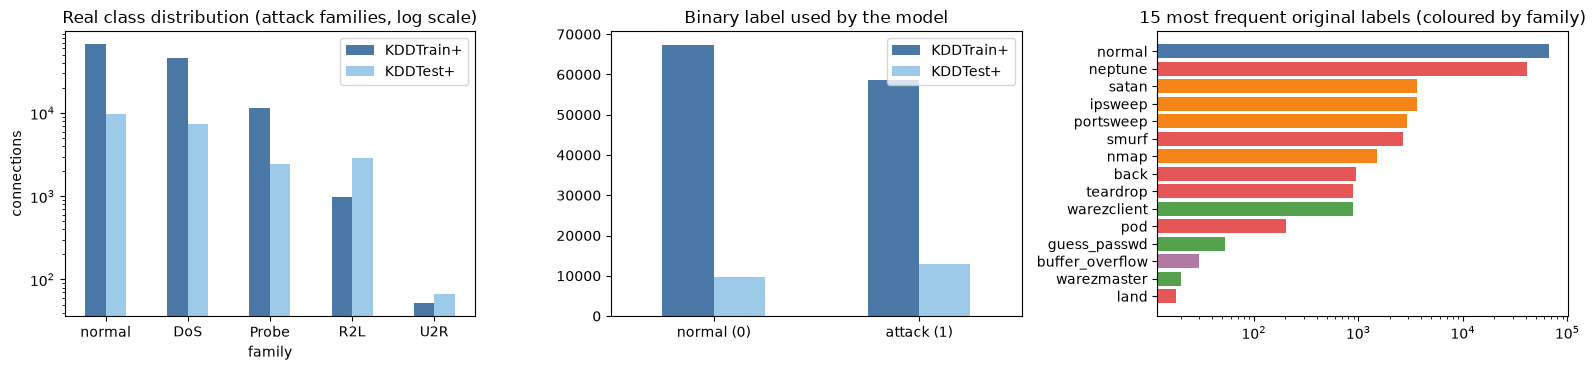

In [7]:
FAM_COLORS = {"normal": "#4c78a8", "DoS": "#e45756", "Probe": "#f58518", "R2L": "#54a24b", "U2R": "#b279a2"}
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
cnt = pd.DataFrame({"KDDTrain+": train_raw.family.value_counts().reindex(FAMILIES),
                    "KDDTest+": test_raw.family.value_counts().reindex(FAMILIES)})
cnt.plot.bar(ax=ax[0], color=["#4c78a8", "#9ecae9"], rot=0); ax[0].set_yscale("log"); ax[0].set_title("Real class distribution (attack families, log scale)"); ax[0].set_ylabel("connections")
bn = pd.DataFrame({"KDDTrain+": train_raw.is_attack.value_counts().sort_index(), "KDDTest+": test_raw.is_attack.value_counts().sort_index()})
bn.index = ["normal (0)", "attack (1)"]; bn.plot.bar(ax=ax[1], color=["#4c78a8", "#9ecae9"], rot=0); ax[1].set_title("Binary label used by the model")
top = train_raw.label.value_counts().head(15)[::-1]
ax[2].barh(top.index, top.values, color=[FAM_COLORS[ATTACK_FAMILY[l]] for l in top.index]); ax[2].set_xscale("log"); ax[2].set_title("15 most frequent original labels (coloured by family)")
plt.tight_layout(); plt.show()

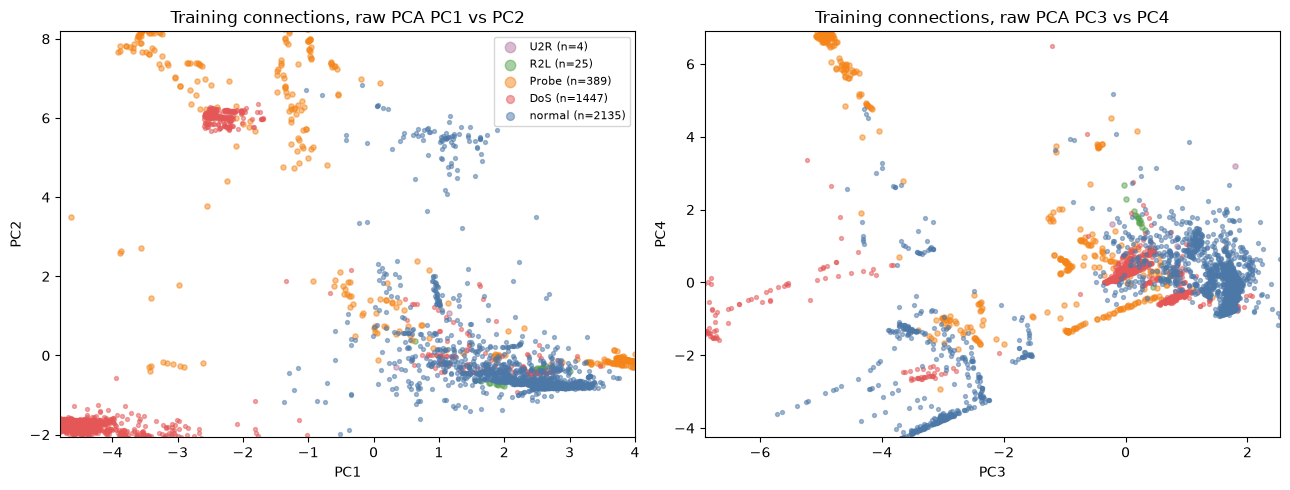

In [8]:
# Raw PCA coordinates of the real training connections (PCA fitted on the training pool), coloured by ground-truth family
Z_tr = to_pca(X_tr_raw)
order = np.argsort([FAMILIES.index(f) for f in fam_tr])[::-1]      # draw the big classes first, small ones on top
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for k, (i, j) in enumerate([(0, 1), (2, 3)]):
    for fam in FAMILIES[::-1]:
        m = fam_tr == fam
        ax[k].scatter(Z_tr[m, i], Z_tr[m, j], s=8 if fam in ("normal", "DoS") else 14, alpha=0.5, color=FAM_COLORS[fam], label=f"{fam} (n={m.sum()})")
    ax[k].set_xlabel(f"PC{i+1}"); ax[k].set_ylabel(f"PC{j+1}"); ax[k].set_title(f"Training connections, raw PCA PC{i+1} vs PC{j+1}")
    ax[k].set_xlim(*np.percentile(Z_tr[:, i], [0.5, 99.5])); ax[k].set_ylim(*np.percentile(Z_tr[:, j], [0.5, 99.5]))
ax[0].legend(markerscale=2, fontsize=8)
plt.tight_layout(); plt.show()

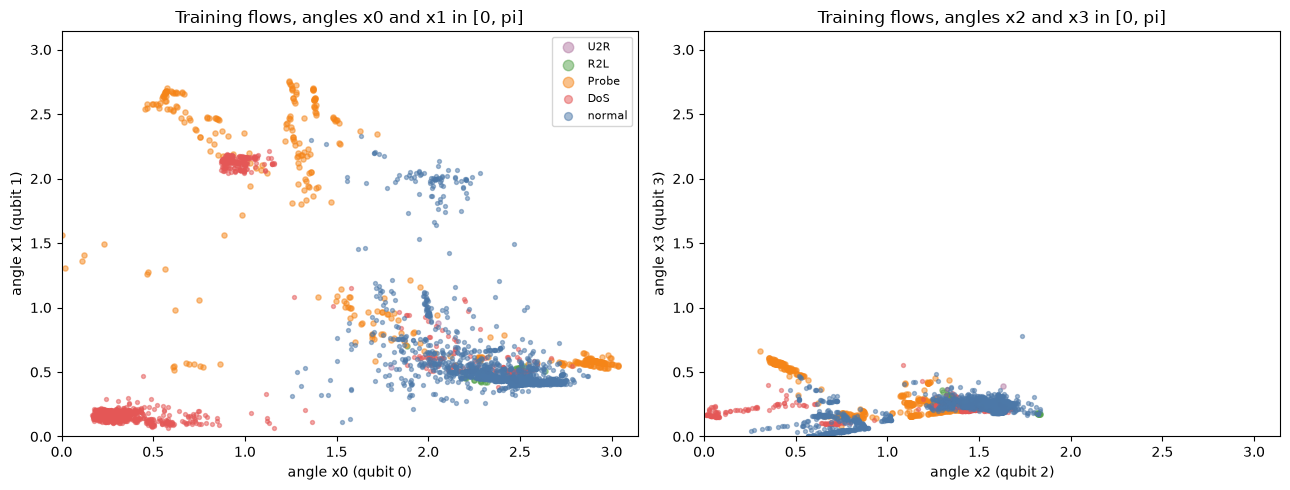

angle range of the training set per qubit: [0.   0.06 0.01 0.   0.   1.9  2.17 1.98] [3.04 2.76 1.83 0.78 0.51 3.08 2.84 2.74]


In [9]:
# The same points as the circuit sees them: PCA scores rescaled to [0, pi] (the angles of the Ry(x_j) encoding gates)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for k, (i, j) in enumerate([(0, 1), (2, 3)]):
    for fam in FAMILIES[::-1]:
        m = fam_tr == fam
        ax[k].scatter(A_tr[m, i], A_tr[m, j], s=8 if fam in ("normal", "DoS") else 14, alpha=0.5, color=FAM_COLORS[fam], label=fam)
    ax[k].set_xlabel(f"angle x{i} (qubit {i})"); ax[k].set_ylabel(f"angle x{j} (qubit {j})"); ax[k].set_xlim(0, np.pi); ax[k].set_ylim(0, np.pi)
    ax[k].set_title(f"Training flows, angles x{i} and x{j} in [0, pi]")
ax[0].legend(markerscale=2, fontsize=8)
plt.tight_layout(); plt.show()
print("angle range of the training set per qubit:", np.round(A_tr.min(0), 2), np.round(A_tr.max(0), 2))

### Non-IID partition over the edge nodes

Table III only says "Non-IID". Each of the five classes is split over the 10 nodes with proportions drawn from a Dirichlet($\alpha=0.5$) (every node keeps at least 20 rows), so
a node sees a skewed mixture of attack families, as in a real smart-city deployment where different gateways face different traffic.

,normal,DoS,Probe,R2L,U2R,total,attack_share
node 0,198,73,99,13,0,383,0.48
node 1,364,11,0,5,0,380,0.04
node 2,476,358,144,1,0,979,0.51
node 3,308,738,19,1,0,1066,0.71
node 4,7,133,0,1,0,141,0.95
node 5,4,40,0,1,1,46,0.91
node 6,3,10,10,0,2,25,0.88
node 7,20,14,0,1,0,35,0.43
node 8,680,61,116,0,0,857,0.21
node 9,75,9,1,2,1,88,0.15


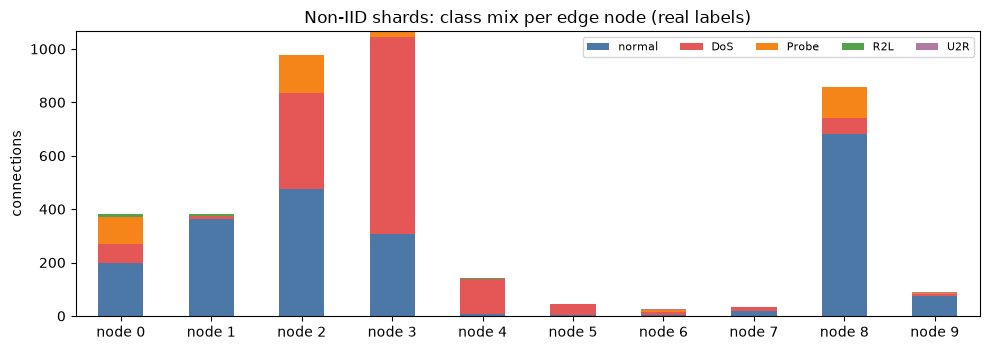

In [10]:
def dirichlet_split(labels, n_nodes, alpha, rng, min_size=20):
    while True:
        parts = [[] for _ in range(n_nodes)]
        for c in np.unique(labels):
            idx = np.where(labels == c)[0]; rng.shuffle(idx)
            p = rng.dirichlet(alpha * np.ones(n_nodes)); cuts = (np.cumsum(p) * len(idx)).astype(int)[:-1]
            for i, chunk in enumerate(np.split(idx, cuts)):
                parts[i] += chunk.tolist()
        if min(len(p) for p in parts) >= min_size:
            return [np.array(p) for p in parts]

PARTS = dirichlet_split(fam_tr, N_NODES, DIRICHLET_ALPHA, np.random.default_rng(SEED))
comp = pd.DataFrame({f"node {i}": pd.Series(fam_tr[p]).value_counts().reindex(FAMILIES).fillna(0).astype(int) for i, p in enumerate(PARTS)}).T
display(comp.assign(total=comp.sum(1), attack_share=[round(float(y_tr[p].mean()), 2) for p in PARTS]))
comp[FAMILIES].plot.bar(stacked=True, figsize=(10, 3.6), color=[FAM_COLORS[f] for f in FAMILIES], rot=0)
plt.ylabel("connections"); plt.title("Non-IID shards: class mix per edge node (real labels)"); plt.legend(ncol=5, fontsize=8); plt.tight_layout(); plt.show()

## 3. The quantum client: simulator, parameter-shift rule and light-cone check

**Circuit (Eq. 1, Fig. 3).** Qubits start in $|0\rangle$; $R_y(x_j)$ on qubit $j$ encodes the 8 angles; then 4 times: $R_y(\theta)$ on every qubit,
a cascade of nearest-neighbour CNOTs, $R_z(\theta)$ on every qubit. The output is $\hat y=\langle Z_0\rangle$.

**Simulator.** The paper trains with "statevector_simulator" and the parameter-shift rule. A circuit run per parameter and shift, per training row, is costly in
PennyLane or Qiskit (the paper reports 2.5 minutes per node and local epoch), so we use a small batched NumPy state-vector simulator that evolves all shifted copies
of a mini-batch at once and branches the shifted circuits off the base circuit at the gate being shifted. It is built from **one gate list**
that also generates the circuit drawings, and it is cross-checked against PennyLane (`default.qubit`, back-propagation) in the circuit section below.

**Exact parameter-shift saving.** A static Heisenberg-picture analysis of the observable $Z_0$ finds the trainable gates whose parameter can change
$\langle Z_0\rangle$ at all. For all other parameters the gradient is exactly zero and their shifted circuits are skipped (this changes nothing numerically; the check
cell verifies it against brute force).

In [11]:
DT = np.complex64   # state-vector precision (float32 amplitudes are plenty for 1e-5 accuracy)


def build_gate_list(n_qubits=N_QUBITS, n_layers=N_LAYERS, entangler="cascade_up"):
    """Gate list of the F-VQML client circuit = single source of truth for the simulator AND the drawings.
    Each entry is (kind, qubits, index): ('RYX', j, j) data-encoding Ry(x_j);
    ('RY'|'RZ', j, k) trainable rotation with parameter index k; ('CNOT', (control, target), None)."""
    gates, k = [], 0
    for j in range(n_qubits):
        gates.append(("RYX", j, j))
    for _ in range(n_layers):
        for j in range(n_qubits):
            gates.append(("RY", j, k)); k += 1
        # CHOICE: Fig. 3 only says "a cascade of entangling CNOT gates" with nearest-neighbour topology.
        #   cascade_up   : CNOT(0,1), CNOT(1,2), ..., CNOT(n-2,n-1)   (literal reading, default)
        #   cascade_down : CNOT(n-2,n-1), ..., CNOT(1,2), CNOT(0,1)   (ablation: every qubit can reach qubit 0)
        order = range(n_qubits - 1) if entangler == "cascade_up" else range(n_qubits - 2, -1, -1)
        for j in order:
            gates.append(("CNOT", (j, j + 1), None))
        for j in range(n_qubits):
            gates.append(("RZ", j, k)); k += 1
    return gates, k


def relevant_params(gates, n_params, n_qubits=N_QUBITS):
    """Static Heisenberg-picture light-cone analysis of the observable Z_0.
    Walk the circuit backwards and track which Pauli letters (X, Y, Z) the observable can contain on each qubit.
    A trainable gate whose parameter cannot change <Z_0> gets gradient exactly 0, so the parameter-shift rule
    does not need to run its two shifted circuits (an exact saving, no approximation)."""
    letters = [set() for _ in range(n_qubits)]
    letters[0] = {"Z"}
    rel = np.zeros(n_params, dtype=bool)
    for kind, q, k in reversed(gates):
        if kind == "RYX":
            continue
        if kind == "CNOT":
            c, t = q
            if letters[c] & {"X", "Y"}: letters[t].add("X")      # X_c -> X_c X_t, Y_c -> Y_c X_t
            if letters[t] & {"Y", "Z"}: letters[c].add("Z")      # Z_t -> Z_c Z_t, Y_t -> Z_c Y_t
        elif kind == "RY":                                       # Ry mixes X and Z, leaves Y alone
            if letters[q] & {"X", "Z"}:
                rel[k] = True; letters[q] |= {"X", "Z"}
        elif kind == "RZ":                                       # Rz mixes X and Y, leaves Z alone
            if letters[q] & {"X", "Y"}:
                rel[k] = True; letters[q] |= {"X", "Y"}
    return rel


def encode_state(x):
    """Product state after the Ry(x_j) encoding layer, shape (2**n, B); qubit 0 = most significant bit."""
    B, n = x.shape
    psi = np.ones((1, B), dtype=DT)
    for j in range(n):
        v = np.stack([np.cos(x[:, j] / 2), np.sin(x[:, j] / 2)], axis=0).astype(DT)   # (2,B)
        psi = (psi[:, None, :] * v[None, :, :]).reshape(-1, B)
    return psi


def apply_gate(S, kind, q, ang, n=N_QUBITS):
    """In-place gate on a stack S of shape (R, 2**n, B); the angle is the same for the whole stack."""
    R, _, B = S.shape
    if kind == "CNOT":
        c, t = q
        a = S.reshape(R, 2 ** c, 2, 2 ** (t - c - 1), 2, 2 ** (n - t - 1) * B)
        sub = a[:, :, 1]
        tmp = sub[:, :, :, 0].copy(); sub[:, :, :, 0] = sub[:, :, :, 1]; sub[:, :, :, 1] = tmp
    elif kind == "RY":
        a = S.view(np.float32).reshape(R, 2 ** q, 2, 2 ** (n - q - 1) * B * 2)   # Ry is real: re/im parts mix identically
        a0 = a[:, :, 0, :].copy(); a1 = a[:, :, 1, :]
        cc, ss = np.float32(np.cos(ang / 2)), np.float32(np.sin(ang / 2))
        np.multiply(a1, -ss, out=a[:, :, 0, :]); a[:, :, 0, :] += cc * a0
        a1 *= cc; a1 += ss * a0
    elif kind == "RZ":
        a = S.reshape(R, 2 ** q, 2, 2 ** (n - q - 1) * B)
        e = DT(np.exp(-1j * ang / 2))
        a[:, :, 0, :] *= e; a[:, :, 1, :] *= np.conj(e)
    else:
        raise ValueError(kind)


def z0_per_sample(S):
    R, dim, B = S.shape
    p = np.abs(S.reshape(R, 2, dim // 2, B)) ** 2
    return (p[:, 0].sum(1) - p[:, 1].sum(1)).astype(np.float64)   # (R,B)


def forward(x, theta, gates):
    """Ideal <Z_0> for every row of x (statevector). x: (B,n) angles, theta: (P,). Returns (B,)."""
    S = encode_state(x)[None]
    for kind, q, k in gates:
        if kind != "RYX":
            apply_gate(S, kind, q, None if kind == "CNOT" else theta[k])
    return z0_per_sample(S)[0]


def forward_parameter_shift(x, theta, gates, rel):
    """Exact parameter-shift evaluation (Eq. 3 applied to the model output):
    returns f = <Z_0>(theta), f_plus[k] = <Z_0>(theta + pi/2 e_k), f_minus[k] = <Z_0>(theta - pi/2 e_k)
    for all P parameters (shape (P,B)); irrelevant parameters (light cone) are filled with f (gradient 0).
    The shifted circuits share the prefix before gate k with the base circuit, so they are branched off there."""
    P = len(theta); B = x.shape[0]; n_rel = int(rel.sum())
    stack = np.zeros((1 + 2 * n_rel, 2 ** x.shape[1], B), dtype=DT)
    stack[0] = encode_state(x); cnt = 1; slot = {}
    for kind, q, k in gates:
        if kind == "RYX":
            continue
        if kind == "CNOT":
            apply_gate(stack[:cnt], kind, q, None); continue
        if rel[k]:
            for sgn in (+1, -1):
                stack[cnt] = stack[0]
                apply_gate(stack[cnt:cnt + 1], kind, q, theta[k] + sgn * np.pi / 2)
                cnt += 1
            slot[k] = cnt - 2
        apply_gate(stack[:cnt - (2 if rel[k] else 0)], kind, q, theta[k])
    z = z0_per_sample(stack)
    f = z[0]
    fp = np.repeat(f[None], P, 0); fm = fp.copy()
    for k, s in slot.items():
        fp[k] = z[s]; fm[k] = z[s + 1]
    return f, fp, fm

In [12]:
# ---- sanity checks of the simulator ----
GATES, N_PARAMS = build_gate_list(N_QUBITS, N_LAYERS, "cascade_up")
REL = relevant_params(GATES, N_PARAMS)
assert N_PARAMS == 2 * N_QUBITS * N_LAYERS == 64
chk = np.random.default_rng(0)
xs = chk.uniform(0, np.pi, (8, N_QUBITS)); th = chk.uniform(-np.pi, np.pi, N_PARAMS)
f, fp, fm = forward_parameter_shift(xs, th, GATES, REL)
assert np.allclose(f, forward(xs, th, GATES), atol=1e-6)
g_ps = 0.5 * (fp - fm)                                                    # parameter-shift gradient of the output, shape (P,B)
h = 1e-2
g_fd = np.zeros_like(g_ps)
for k in range(N_PARAMS):                                                # central finite differences, brute force over all 64 parameters
    t1, t2 = th.copy(), th.copy(); t1[k] += h; t2[k] -= h
    g_fd[k] = (forward(xs, t1, GATES) - forward(xs, t2, GATES)) / (2 * h)
print("max |parameter-shift - finite difference| over all 64 parameters:", float(np.abs(g_ps - g_fd).max()))
assert np.abs(g_ps - g_fd).max() < 2e-3
brute_nonzero = np.abs(g_fd).max(1) > 1e-4
print("parameters with non-zero gradient (brute force):", int(brute_nonzero.sum()), "| light-cone analysis says:", int(REL.sum()))
assert (brute_nonzero == REL).all()
print("OK: parameter-shift gradient verified, light-cone analysis exact.")

max |parameter-shift - finite difference| over all 64 parameters: 3.5762786865234375e-05
parameters with non-zero gradient (brute force): 16 | light-cone analysis says: 16
OK: parameter-shift gradient verified, light-cone analysis exact.


## Quantum Circuit Architecture

The figure below is the circuit that the simulator executes, drawn from the *same* gate list (`GATES`) by building a PennyLane QNode on `default.qubit`; the next cell asserts
that this QNode and the NumPy simulator return the same $\langle Z_0\rangle$ and the same gradient. The first 8 gates are the data-encoding rotations $R_y(x_j)$ (shown with a
real example row), the remaining ones are trainable ($R_y(\theta)$, CNOT cascade, $R_z(\theta)$ per layer; the printed angles are the random initial parameters).

**Assumptions where the paper is silent:** Fig. 3 draws one layer for 4 qubits only and does not give the direction or order of the CNOT cascade. We use `CNOT(j, j+1)` for
$j = 0..6$ in ascending order ("cascade_up") as the default. Measurement: Pauli-Z expectation of qubit 0. A second architecture, the same layers with the CNOTs in descending order
("cascade_down"), is drawn and trained as an ablation. The depolarizing noise of Section IV is not a gate in the diagram; it is applied after every one of the 64 trainable gates in the
noisy runs (see the noise section).

[cascade_up (default)] qubits = 8 | depth = 22 (own count 22) | gates = 100 | trainable parameters = 64 (Ry: 32, Rz: 32) | parameters that can influence <Z0>: 16


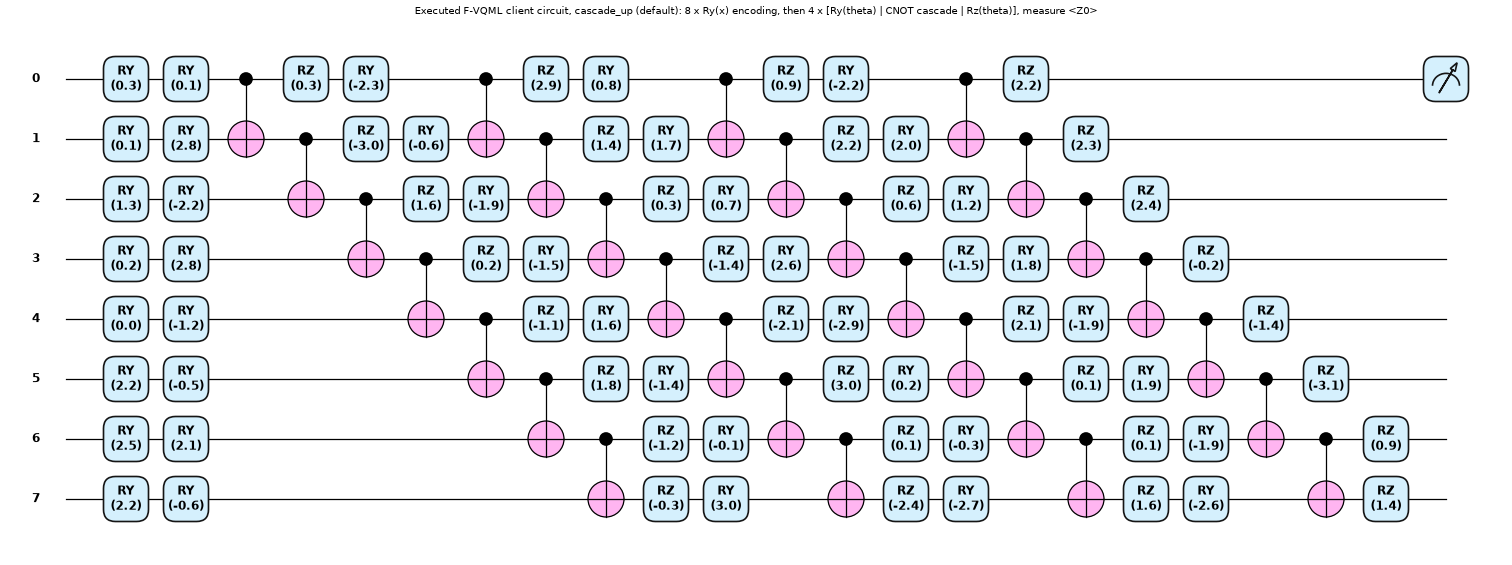

[cascade_down (ablation)] qubits = 8 | depth = 22 (own count 22) | gates = 100 | trainable parameters = 64 (Ry: 32, Rz: 32) | parameters that can influence <Z0>: 42


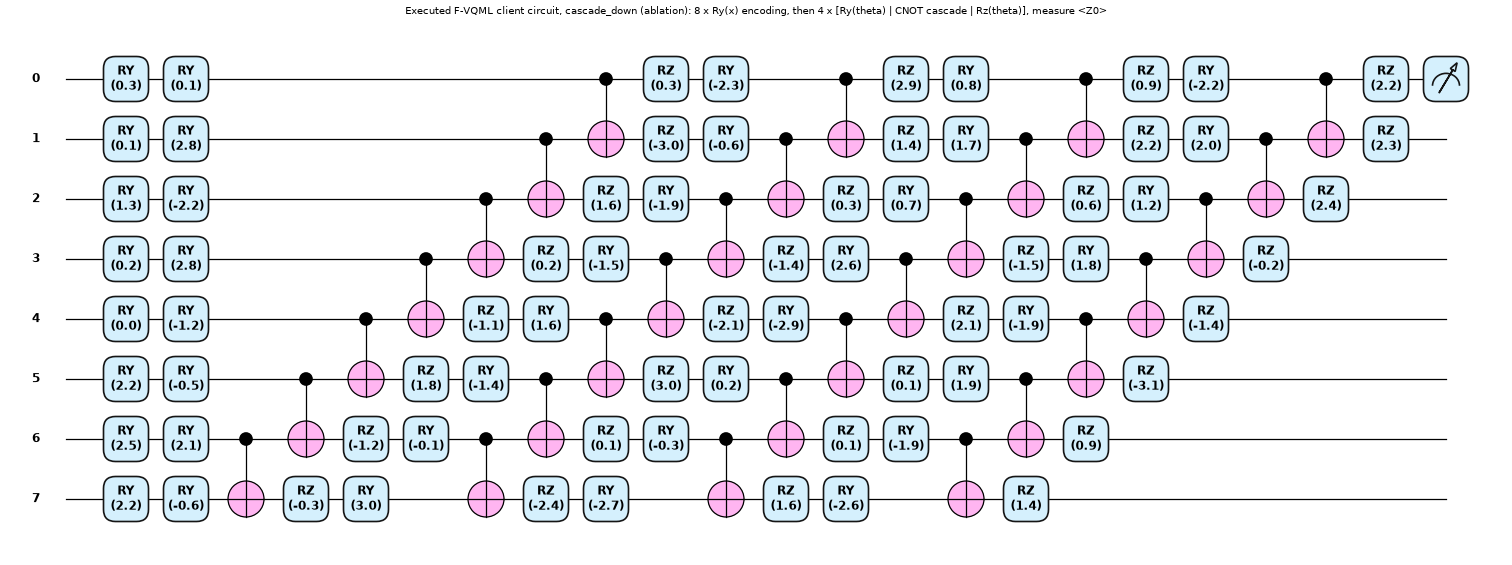

In [13]:
dev = qml.device("default.qubit", wires=N_QUBITS)
def make_qnode(gates):
    @qml.qnode(dev, diff_method="backprop")
    def circuit(x, theta):
        for kind, q, k in gates:
            if kind == "RYX":  qml.RY(x[q], wires=q)               # data encoding, Eq. 1
            elif kind == "RY": qml.RY(theta[k], wires=q)           # trainable
            elif kind == "RZ": qml.RZ(theta[k], wires=q)           # trainable
            else:              qml.CNOT(wires=list(q))             # entangling cascade
        return qml.expval(qml.PauliZ(0))
    return circuit

def manual_depth(gates, n=N_QUBITS):
    t = [0] * n
    for kind, q, k in gates:
        qs = list(q) if kind == "CNOT" else [q]
        d = max(t[w] for w in qs) + 1
        for w in qs: t[w] = d
    return max(t)

ARCHS = {"cascade_up (default)": "cascade_up", "cascade_down (ablation)": "cascade_down"}
x_demo = A_tr[0]; theta_demo = np.random.default_rng(1).uniform(-np.pi, np.pi, N_PARAMS)
for name, ent in ARCHS.items():
    gts, P = build_gate_list(N_QUBITS, N_LAYERS, ent); qn = make_qnode(gts); rel = relevant_params(gts, P)
    spec = qml.specs(qn)(x_demo, theta_demo)
    print(f"[{name}] qubits = {N_QUBITS} | depth = {spec['resources'].depth} (own count {manual_depth(gts)}) | gates = {spec['resources'].num_gates} "
          f"| trainable parameters = {P} (Ry: {P//2}, Rz: {P//2}) | parameters that can influence <Z0>: {int(rel.sum())}")
    fig, ax = qml.draw_mpl(qn, decimals=1, style="pennylane")(x_demo, theta_demo)
    fig.set_dpi(60); ax.set_title(f"Executed F-VQML client circuit, {name}: 8 x Ry(x) encoding, then {N_LAYERS} x [Ry(theta) | CNOT cascade | Rz(theta)], measure <Z0>", fontsize=12)
    plt.show()

In [14]:
# equivalence of the drawn circuit (PennyLane) and the simulator that does the training, for both architectures
for name, ent in ARCHS.items():
    gts, P = build_gate_list(N_QUBITS, N_LAYERS, ent); qn = make_qnode(gts); rel = relevant_params(gts, P)
    xs = np.random.default_rng(5).uniform(0, np.pi, (12, N_QUBITS)); th = np.random.default_rng(6).uniform(-np.pi, np.pi, P)
    ref = np.array([float(qn(x, th)) for x in xs])
    f, fp, fm = forward_parameter_shift(xs, th, gts, rel)
    gref = np.stack([np.asarray(qml.grad(lambda t_, x=x: qn(x, t_))(pnp.array(th, requires_grad=True))) for x in xs[:4]], axis=1)
    d_out = np.abs(ref - f).max(); d_grad = np.abs(gref - 0.5 * (fp - fm)[:, :4]).max()
    print(f"{name}: max |<Z0> PennyLane - simulator| = {d_out:.1e} | max |gradient PennyLane(backprop) - parameter-shift| = {d_grad:.1e}")
    assert d_out < 1e-5 and d_grad < 1e-5
print("OK: the drawn circuit and the trained circuit are the same.")

cascade_up (default): max |<Z0> PennyLane - simulator| = 2.5e-07 | max |gradient PennyLane(backprop) - parameter-shift| = 3.1e-07


cascade_down (ablation): max |<Z0> PennyLane - simulator| = 1.8e-07 | max |gradient PennyLane(backprop) - parameter-shift| = 4.4e-07
OK: the drawn circuit and the trained circuit are the same.


cascade_up (default): input features that influence <Z0> = [0, 1, 2, 3] | trainable parameters that influence <Z0> = 16 of 64


cascade_down (ablation): input features that influence <Z0> = [0, 1, 2, 3, 4, 5, 6, 7] | trainable parameters that influence <Z0> = 42 of 64


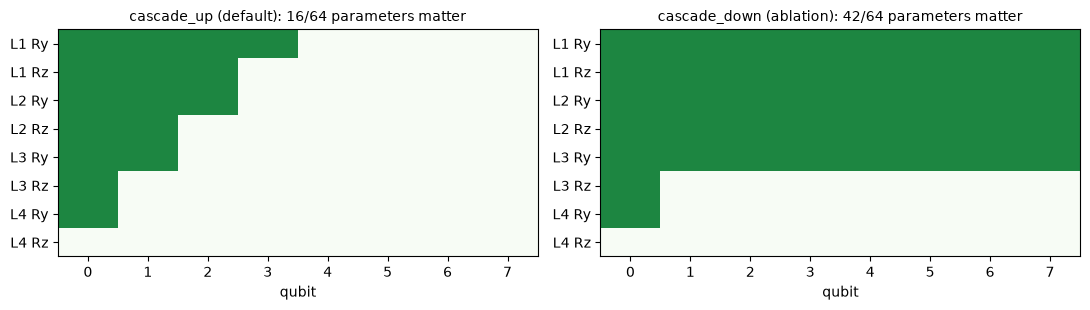

In [15]:
# Which inputs and parameters can the output depend on? (cascade_up = literal reading of Fig. 3)
INFLUENCE = {}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for a, (name, ent) in zip(ax, ARCHS.items()):
    gts, P = build_gate_list(N_QUBITS, N_LAYERS, ent); rel = relevant_params(gts, P)
    grid = np.zeros((2 * N_LAYERS, N_QUBITS))
    for kind, q, k in gts:
        if kind in ("RY", "RZ"): grid[(k // (2 * N_QUBITS)) * 2 + (kind == "RZ"), q] = rel[k]
    a.imshow(grid, cmap="Greens", vmin=0, vmax=1.3, aspect="auto"); a.set_xlabel("qubit"); a.set_yticks(range(2 * N_LAYERS))
    a.set_yticklabels([f"L{l+1} {g}" for l in range(N_LAYERS) for g in ("Ry", "Rz")]); a.set_title(f"{name}: {int(rel.sum())}/{P} parameters matter", fontsize=10)
    xs = np.random.default_rng(3).uniform(0, np.pi, (16, N_QUBITS)); th = np.random.default_rng(4).uniform(-np.pi, np.pi, P); base = forward(xs, th, gts)
    infl = [j for j in range(N_QUBITS) if np.abs(forward(np.where(np.arange(N_QUBITS) == j, xs + 0.5, xs), th, gts) - base).max() > 1e-6]
    INFLUENCE[name] = infl
    print(f"{name}: input features that influence <Z0> = {infl} | trainable parameters that influence <Z0> = {int(rel.sum())} of {P}")
plt.tight_layout(); plt.show()

## 4. Federated Quantum Averaging (Algorithm 1)

One communication round, exactly as in Algorithm 1: the PS broadcasts $\theta_G$; every node copies it, performs `LOCAL_EPOCHS` local steps, each on a random mini-batch of its own shard, with the
gradient from the parameter-shift rule, and uploads $\Delta\theta_i=\theta_i-\theta_G$; the PS sets $\theta_G\leftarrow\theta_G+\frac1N\sum_i\Delta\theta_i$.

* **Loss.** $p=(1+\hat y)/2$ is the probability of "attack"; binary cross-entropy. The parameter-shift rule is applied to the circuit output, $\partial_k\hat y=\tfrac12[\hat y(\theta_k+\pi/2)-\hat y(\theta_k-\pi/2)]$, and the BCE derivative is chained on top (applying Eq. 3 to the loss itself would not be exact because the loss is not a sinusoid in $\theta_k$).
* **Noise (Section IV).** With the literal Eq. 4 channel after each of the 64 trainable gates, $\langle Z_0\rangle_{\rm noisy}=(1-\lambda)^{64}\langle Z_0\rangle_{\rm ideal}=0.53\,\langle Z_0\rangle_{\rm ideal}$, the same factor on every shifted evaluation
  and hence on the gradient (Eq. 6). Optionally every circuit run returns a finite-shot estimate (`SHOTS`), which is the zero-mean noise $\epsilon_i$ that the paper argues averages out over nodes.
  Predictions use the sign of the expectation value (the attenuation cannot change it), i.e. noise acts on training only.

In [16]:
def metrics(y_true, y_pred):
    out = {"accuracy": accuracy_score(y_true, y_pred)}
    for avg in ("macro", "micro"):
        p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average=avg, zero_division=0)
        out.update({f"precision_{avg}": p, f"recall_{avg}": r, f"f1_{avg}": f})
    return out

def readout(f, fp, fm, atten, shots, rng):
    """Apply the (global depolarizing) attenuation and optional finite-shot sampling to the three kinds of circuit runs."""
    if shots is None:
        return atten * f, atten * fp, atten * fm
    smp = lambda z: 2.0 * rng.binomial(shots, np.clip((1 + atten * z) / 2, 0, 1)) / shots - 1.0
    return smp(f), smp(fp), smp(fm)

def bce_gradient(f, fp, fm, y):
    p = np.clip((1 + f) / 2, 1e-6, 1 - 1e-6)
    dL_dyhat = 0.5 * (-(y / p) + (1 - y) / (1 - p))                       # d BCE / d yhat per sample
    return ((0.5 * (fp - fm)) * dL_dyhat[None, :]).mean(1)                # chain rule with the parameter-shift output gradient

def run_fedqa(entangler="cascade_up", lam=0.0, shots=None, seed=0, rounds=ROUNDS, verbose=True, tag=""):
    gates, P = build_gate_list(N_QUBITS, N_LAYERS, entangler); rel = relevant_params(gates, P)
    rg = np.random.default_rng(1000 + seed)
    theta_g = rg.uniform(-np.pi, np.pi, P)                                # CHOICE: uniform initialisation
    atten = (1 - lam) ** P                                                # one depolarizing channel per trainable gate (Eq. 4-6)
    acc_hist, loss_hist = [], []; t0 = time.time()
    for r in range(rounds):
        deltas = []; loss_r = []
        for i in range(N_NODES):
            th = theta_g.copy()
            for e in range(LOCAL_EPOCHS):
                idx = rg.choice(PARTS[i], size=min(BATCH, len(PARTS[i])), replace=False)
                f, fp, fm = forward_parameter_shift(A_tr[idx], th, gates, rel)
                f, fp, fm = readout(f, fp, fm, atten, shots, rg)
                th = th - LR * bce_gradient(f, fp, fm, y_tr[idx])
                p = np.clip((1 + f) / 2, 1e-6, 1 - 1e-6); loss_r.append(float(-(y_tr[idx] * np.log(p) + (1 - y_tr[idx]) * np.log(1 - p)).mean()))
            deltas.append(th - theta_g)
        theta_g = theta_g + np.mean(deltas, axis=0)                       # Algorithm 1, line 15 (unweighted mean)
        acc_hist.append(float(((forward(A_ho, theta_g, gates) > 0).astype(int) == y_ho).mean())); loss_hist.append(float(np.mean(loss_r)))
        if verbose and (r % max(1, rounds // 5) == 0 or r == rounds - 1):
            print(f"  {tag} seed {seed} round {r+1:2d}/{rounds}: train BCE {loss_hist[-1]:.3f} | held-out accuracy {acc_hist[-1]:.3f} | {time.time()-t0:.0f}s", flush=True)
    pred_ho = (forward(A_ho, theta_g, gates) > 0).astype(int); pred_kt = (forward(A_kt, theta_g, gates) > 0).astype(int)
    return dict(theta=theta_g, gates=gates, acc_hist=acc_hist, loss_hist=loss_hist, time=time.time() - t0,
                holdout=metrics(y_ho, pred_ho), kddtest=metrics(y_kt, pred_kt), pred_ho=pred_ho, pred_kt=pred_kt)

RESULTS = {}

### 4.1 Ideal (noise-free) F-VQML

In [17]:
t0 = time.time()
RESULTS["F-VQML ideal"] = [run_fedqa("cascade_up", 0.0, None, s, tag="ideal") for s in RUN_SEEDS]
print(f"done in {time.time()-t0:.0f}s | final held-out accuracy per seed:", [round(r["holdout"]["accuracy"], 4) for r in RESULTS["F-VQML ideal"]])

  ideal seed 0 round  1/50: train BCE 0.475 | held-out accuracy 0.855 | 9s


  ideal seed 0 round 11/50: train BCE 0.361 | held-out accuracy 0.886 | 77s


  ideal seed 0 round 21/50: train BCE 0.344 | held-out accuracy 0.887 | 150s


  ideal seed 0 round 31/50: train BCE 0.296 | held-out accuracy 0.887 | 210s


  ideal seed 0 round 41/50: train BCE 0.295 | held-out accuracy 0.887 | 273s


...

  ideal seed 2 round 21/50: train BCE 0.325 | held-out accuracy 0.897 | 194s


  ideal seed 2 round 31/50: train BCE 0.287 | held-out accuracy 0.908 | 260s


  ideal seed 2 round 41/50: train BCE 0.279 | held-out accuracy 0.909 | 350s


  ideal seed 2 round 50/50: train BCE 0.271 | held-out accuracy 0.913 | 657s


done in 1337s | final held-out accuracy per seed: [0.887, 0.903, 0.913]


### 4.2 With the paper's depolarizing noise (lambda = 0.01 on every trainable gate)

In [18]:
t0 = time.time()
RESULTS["F-VQML lambda=0.01"] = [run_fedqa("cascade_up", LAMBDA, None, s, tag="noisy") for s in RUN_SEEDS]
print(f"done in {time.time()-t0:.0f}s | final held-out accuracy per seed:", [round(r["holdout"]["accuracy"], 4) for r in RESULTS["F-VQML lambda=0.01"]])

  noisy seed 0 round  1/50: train BCE 0.558 | held-out accuracy 0.825 | 12s


  noisy seed 0 round 11/50: train BCE 0.512 | held-out accuracy 0.886 | 127s


  noisy seed 0 round 21/50: train BCE 0.498 | held-out accuracy 0.886 | 248s


  noisy seed 0 round 31/50: train BCE 0.465 | held-out accuracy 0.887 | 405s


  noisy seed 0 round 41/50: train BCE 0.460 | held-out accuracy 0.886 | 503s


...

  noisy seed 2 round 21/50: train BCE 0.519 | held-out accuracy 0.874 | 173s


  noisy seed 2 round 31/50: train BCE 0.480 | held-out accuracy 0.888 | 252s


  noisy seed 2 round 41/50: train BCE 0.459 | held-out accuracy 0.904 | 338s


  noisy seed 2 round 50/50: train BCE 0.445 | held-out accuracy 0.908 | 417s


done in 1535s | final held-out accuracy per seed: [0.8853, 0.9083, 0.9077]


### 4.3 Depolarizing noise plus finite-shot noise (the zero-mean error that averaging over nodes is claimed to remove)

In [19]:
t0 = time.time()
RESULTS[f"F-VQML lambda=0.01 + {SHOTS} shots"] = [run_fedqa("cascade_up", LAMBDA, SHOTS, s, tag="noisy+shots") for s in RUN_SEEDS]
print(f"done in {time.time()-t0:.0f}s | final held-out accuracy per seed:", [round(r["holdout"]["accuracy"], 4) for r in RESULTS[f"F-VQML lambda=0.01 + {SHOTS} shots"]])

  noisy+shots seed 0 round  1/50: train BCE 0.562 | held-out accuracy 0.826 | 11s


  noisy+shots seed 0 round 11/50: train BCE 0.526 | held-out accuracy 0.886 | 94s


  noisy+shots seed 0 round 21/50: train BCE 0.484 | held-out accuracy 0.886 | 178s


  noisy+shots seed 0 round 31/50: train BCE 0.473 | held-out accuracy 0.886 | 256s


  noisy+shots seed 0 round 41/50: train BCE 0.463 | held-out accuracy 0.886 | 360s


...

  noisy+shots seed 2 round 21/50: train BCE 0.515 | held-out accuracy 0.874 | 90s


  noisy+shots seed 2 round 31/50: train BCE 0.488 | held-out accuracy 0.888 | 139s


  noisy+shots seed 2 round 41/50: train BCE 0.454 | held-out accuracy 0.904 | 185s


  noisy+shots seed 2 round 50/50: train BCE 0.449 | held-out accuracy 0.907 | 221s


done in 905s | final held-out accuracy per seed: [0.8853, 0.9083, 0.9073]


### 4.4 Ablation: CNOT cascade in the opposite order

With `cascade_down` every qubit can reach qubit 0 within one layer (see the light-cone figure), so all 8 input features and 42 of the 64 parameters matter. Fig. 3 does not tell which order the authors used.

In [20]:
t0 = time.time()
RESULTS["ablation cascade_down (ideal)"] = [run_fedqa("cascade_down", 0.0, None, s, tag="cascade_down") for s in ABLATION_SEEDS]
print(f"done in {time.time()-t0:.0f}s | final held-out accuracy per seed:", [round(r["holdout"]["accuracy"], 4) for r in RESULTS["ablation cascade_down (ideal)"]])

  cascade_down seed 0 round  1/50: train BCE 0.634 | held-out accuracy 0.897 | 20s


  cascade_down seed 0 round 11/50: train BCE 0.512 | held-out accuracy 0.906 | 171s


  cascade_down seed 0 round 21/50: train BCE 0.424 | held-out accuracy 0.906 | 307s


  cascade_down seed 0 round 31/50: train BCE 0.357 | held-out accuracy 0.908 | 407s


  cascade_down seed 0 round 41/50: train BCE 0.346 | held-out accuracy 0.908 | 507s


  cascade_down seed 0 round 50/50: train BCE 0.328 | held-out accuracy 0.909 | 595s


done in 596s | final held-out accuracy per seed: [0.9087]


## 5. Classical baselines

* **Federated linear models** (the paper's baseline, "a federated linear model restricted to an identical parameter count"): logistic regression trained with exactly the same FedAvg schedule
  (10 non-IID nodes, 3 local mini-batch steps, rounds, learning rate 0.05) on the same angles. *9 parameters*: the same 8 angles + bias. *64 parameters*: 63 PCA angles + bias (an
  equal-parameter-count reading). A second learning rate is added because the baseline is sensitive to it: 0.5 for the 9-parameter model, and 0.005 for the 64-parameter model (with 63 inputs in $[0,\pi]$ the paper's 0.05 makes the accuracy oscillate from round to round).
* **Federated MLP** (the "deep MLP" of Fig. 6): 122 standardised features -> 128 -> 64 -> 1, scikit-learn, FedAvg over weights and biases, same schedule (learning rate 0.05, plain SGD).
* **Centralised** Random Forest and RBF-SVM (`C=1`, `gamma="scale"`) on the pooled training sample, once on the same 8 angles and once on all 122 standardised features, as a reference for what the data allow.

In [21]:
def run_fed_linear(Xtr_, Xho_, Xkt_, lr, seed=0, rounds=ROUNDS):
    rg = np.random.default_rng(2000 + seed); d = Xtr_.shape[1]
    w = np.zeros(d + 1); acc_hist = []                                     # CHOICE: zero initialisation (convex problem)
    sig = lambda z: 1 / (1 + np.exp(-np.clip(z, -30, 30)))
    for r in range(rounds):
        deltas = []
        for i in range(N_NODES):
            wi = w.copy()
            for e in range(LOCAL_EPOCHS):
                idx = rg.choice(PARTS[i], size=min(BATCH, len(PARTS[i])), replace=False)
                Xb = np.c_[Xtr_[idx], np.ones(len(idx))]
                wi = wi - lr * Xb.T @ (sig(Xb @ wi) - y_tr[idx]) / len(idx)
            deltas.append(wi - w)
        w = w + np.mean(deltas, axis=0)
        acc_hist.append(float((((np.c_[Xho_, np.ones(len(Xho_))] @ w) > 0).astype(int) == y_ho).mean()))
    pr = lambda X: ((np.c_[X, np.ones(len(X))] @ w) > 0).astype(int)
    return dict(acc_hist=acc_hist, holdout=metrics(y_ho, pr(Xho_)), kddtest=metrics(y_kt, pr(Xkt_)), n_params=d + 1, pred_ho=pr(Xho_), pred_kt=pr(Xkt_))

def run_fed_mlp(lr=0.05, seed=0, rounds=ROUNDS):
    rg = np.random.default_rng(3000 + seed)
    glob = MLPClassifier(hidden_layer_sizes=(128, 64), solver="sgd", momentum=0.0, learning_rate_init=lr, batch_size=BATCH, random_state=seed)
    glob.partial_fit(S_tr[:BATCH], y_tr[:BATCH], classes=[0, 1])           # builds the weight arrays; its single warm-up step is discarded below
    ri = np.random.default_rng(seed)
    for c in glob.coefs_: c[...] = ri.normal(0, 0.1, c.shape)          # in place: the optimiser holds references to these arrays
    for b in glob.intercepts_: b[...] = 0.0
    import copy
    acc_hist = []
    for r in range(rounds):
        coefs = [np.zeros_like(c) for c in glob.coefs_]; bias = [np.zeros_like(b) for b in glob.intercepts_]
        for i in range(N_NODES):
            loc = copy.deepcopy(glob)
            for e in range(LOCAL_EPOCHS):
                idx = rg.choice(PARTS[i], size=min(BATCH, len(PARTS[i])), replace=False)
                loc.partial_fit(S_tr[idx], y_tr[idx])
            for a, c in zip(coefs, loc.coefs_): a += c / N_NODES
            for a, b in zip(bias, loc.intercepts_): a += b / N_NODES
        for c_old, c_new in zip(glob.coefs_, coefs): c_old[...] = c_new
        for b_old, b_new in zip(glob.intercepts_, bias): b_old[...] = b_new
        acc_hist.append(float((glob.predict(S_ho) == y_ho).mean()))
    n_params = sum(c.size for c in glob.coefs_) + sum(b.size for b in glob.intercepts_)
    return dict(acc_hist=acc_hist, holdout=metrics(y_ho, glob.predict(S_ho)), kddtest=metrics(y_kt, glob.predict(S_kt)), n_params=n_params, pred_ho=glob.predict(S_ho), pred_kt=glob.predict(S_kt))

t0 = time.time()
RESULTS["Fed. linear, 9 params, lr 0.05"] = [run_fed_linear(A_tr, A_ho, A_kt, 0.05, s) for s in RUN_SEEDS]
RESULTS["Fed. linear, 9 params, lr 0.5"] = [run_fed_linear(A_tr, A_ho, A_kt, 0.5, s) for s in RUN_SEEDS]
RESULTS["Fed. linear, 64 params, lr 0.05"] = [run_fed_linear(B_tr, B_ho, B_kt, 0.05, s) for s in RUN_SEEDS]
RESULTS["Fed. linear, 64 params, lr 0.005"] = [run_fed_linear(B_tr, B_ho, B_kt, 0.005, s) for s in RUN_SEEDS]
RESULTS["Fed. MLP (122-128-64-1)"] = [run_fed_mlp(0.05, s) for s in RUN_SEEDS]
print(f"federated baselines done in {time.time()-t0:.0f}s")
for k in list(RESULTS)[-5:]:
    print(f"{k:34s} final held-out accuracy {np.mean([r['holdout']['accuracy'] for r in RESULTS[k]]):.3f}  (parameters: {RESULTS[k][0]['n_params']})")

federated baselines done in 34s
Fed. linear, 9 params, lr 0.05     final held-out accuracy 0.896  (parameters: 9)
Fed. linear, 9 params, lr 0.5      final held-out accuracy 0.917  (parameters: 9)
Fed. linear, 64 params, lr 0.05    final held-out accuracy 0.899  (parameters: 64)
Fed. linear, 64 params, lr 0.005   final held-out accuracy 0.864  (parameters: 64)
Fed. MLP (122-128-64-1)            final held-out accuracy 0.966  (parameters: 24065)


In [22]:
CENTRAL = {}
t0 = time.time()
for name, (Xa, Xb, Xc) in {"8 angles": (A_tr, A_ho, A_kt), "122 features": (S_tr, S_ho, S_kt)}.items():
    for mname, mk in {"Random Forest": lambda: RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1),
                      "SVC (rbf)": lambda: SVC(kernel="rbf", C=1.0, gamma="scale", random_state=SEED)}.items():
        t1 = time.time(); m = mk().fit(Xa, y_tr)
        CENTRAL[f"{mname} on {name}"] = dict(holdout=metrics(y_ho, m.predict(Xb)), kddtest=metrics(y_kt, m.predict(Xc)), time=time.time() - t1)
print(f"centralised baselines done in {time.time()-t0:.0f}s")
display(pd.DataFrame({k: {"held-out acc": v["holdout"]["accuracy"], "KDDTest+ acc": v["kddtest"]["accuracy"], "train+predict s": v["time"]} for k, v in CENTRAL.items()}).T.round(3))

centralised baselines done in 6s


,held-out acc,KDDTest+ acc,train+predict s
Random Forest on 8 angles,0.991,0.793,2.254
SVC (rbf) on 8 angles,0.961,0.776,0.804
Random Forest on 122 features,0.996,0.786,1.814
SVC (rbf) on 122 features,0.974,0.801,1.391


## 6. Re-drawing the paper's figures and tables

### Fig. 5: convergence over communication rounds
Mean over seeds, shaded band = one standard deviation (a single seed in `FAST_MODE`). The paper's curves end at 94.2 % (ideal), 89.7 % (noisy) and 78.1 % (classical linear).

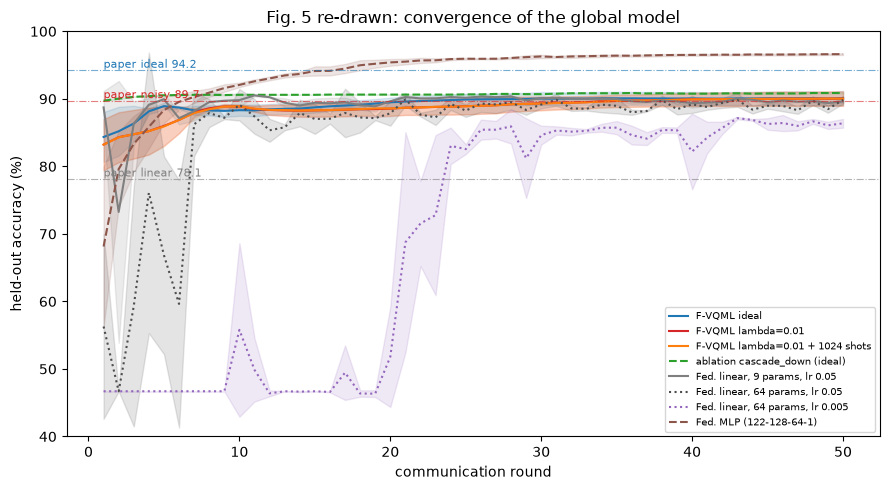

In [23]:
def curve(runs):
    A = np.array([r["acc_hist"] for r in runs]) * 100
    return A.mean(0), A.std(0)
style = {"F-VQML ideal": ("#1f77b4", "-"), "F-VQML lambda=0.01": ("#d62728", "-"), f"F-VQML lambda=0.01 + {SHOTS} shots": ("#ff7f0e", "-"),
         "ablation cascade_down (ideal)": ("#2ca02c", "--"), "Fed. linear, 9 params, lr 0.05": ("#7f7f7f", "-"), "Fed. linear, 64 params, lr 0.05": ("#4d4d4d", ":"),
         "Fed. linear, 64 params, lr 0.005": ("#9467bd", ":"), "Fed. MLP (122-128-64-1)": ("#8c564b", "--")}
fig, ax = plt.subplots(figsize=(9, 5))
for k, (c, ls) in style.items():
    m, s = curve(RESULTS[k]); xs_ = np.arange(1, len(m) + 1)
    ax.plot(xs_, m, color=c, ls=ls, label=k); ax.fill_between(xs_, m - s, m + s, color=c, alpha=0.15)
for val, lab, c in [(94.2, "paper ideal 94.2", "#1f77b4"), (89.7, "paper noisy 89.7", "#d62728"), (78.1, "paper linear 78.1", "#7f7f7f")]:
    ax.axhline(val, color=c, lw=0.8, ls="-.", alpha=0.6); ax.text(ROUNDS * 0.02, val + 0.4, lab, fontsize=8, color=c)
ax.set_xlabel("communication round"); ax.set_ylabel("held-out accuracy (%)"); ax.set_title("Fig. 5 re-drawn: convergence of the global model"); ax.set_ylim(40, 100)
ax.legend(fontsize=7, loc="lower right"); plt.tight_layout(); plt.show()

### Table IV: global-model metrics after the last round (held-out test of `KDDTrain+`, mean over seeds)

In [24]:
rows = []
for k, runs in RESULTS.items():
    for split in ("holdout", "kddtest"):
        df = pd.DataFrame([r[split] for r in runs])
        rows.append({"model": k, "test set": "held-out 20 % of KDDTrain+" if split == "holdout" else "KDDTest+",
                     **{c: f"{100*df[c].mean():.1f}" + (f" +/- {100*df[c].std(ddof=0):.1f}" if len(df) > 1 else "") for c in df.columns}})
TABLE4 = pd.DataFrame(rows)
display(TABLE4[TABLE4["test set"].str.startswith("held")].drop(columns="test set").set_index("model"))
print("\nExtra, harder protocol (KDDTest+ contains 17 attack types never seen in training):")
display(TABLE4[TABLE4["test set"] == "KDDTest+"].drop(columns="test set").set_index("model")[["accuracy", "precision_macro", "recall_macro", "f1_macro"]])

,accuracy,precision_macro,recall_macro,f1_macro,precision_micro,recall_micro,f1_micro
model,,,,,,,
F-VQML ideal,90.1 +/- 1.1,91.2 +/- 1.3,89.6 +/- 1.0,89.9 +/- 1.1,90.1 +/- 1.1,90.1 +/- 1.1,90.1 +/- 1.1
F-VQML lambda=0.01,90.0 +/- 1.1,91.3 +/- 1.3,89.5 +/- 1.0,89.8 +/- 1.1,90.0 +/- 1.1,90.0 +/- 1.1,90.0 +/- 1.1
F-VQML lambda=0.01 + 1024 shots,90.0 +/- 1.1,91.3 +/- 1.3,89.5 +/- 1.0,89.8 +/- 1.1,90.0 +/- 1.1,90.0 +/- 1.1,90.0 +/- 1.1
ablation cascade_down (ideal),90.9,92.2,90.3,90.7,90.9,90.9,90.9
"Fed. linear, 9 params, lr 0.05",89.6 +/- 0.1,90.4 +/- 0.2,89.2 +/- 0.1,89.4 +/- 0.1,89.6 +/- 0.1,89.6 +/- 0.1,89.6 +/- 0.1
"Fed. linear, 9 params, lr 0.5",91.7 +/- 0.0,91.8 +/- 0.1,91.5 +/- 0.0,91.6 +/- 0.0,91.7 +/- 0.0,91.7 +/- 0.0,91.7 +/- 0.0
"Fed. linear, 64 params, lr 0.05",89.9 +/- 0.6,90.5 +/- 0.8,89.4 +/- 0.5,89.7 +/- 0.5,89.9 +/- 0.6,89.9 +/- 0.6,89.9 +/- 0.6
"Fed. linear, 64 params, lr 0.005",86.4 +/- 0.6,86.3 +/- 0.7,86.4 +/- 0.6,86.3 +/- 0.6,86.4 +/- 0.6,86.4 +/- 0.6,86.4 +/- 0.6
Fed. MLP (122-128-64-1),96.6 +/- 0.1,96.6 +/- 0.1,96.6 +/- 0.1,96.6 +/- 0.1,96.6 +/- 0.1,96.6 +/- 0.1,96.6 +/- 0.1



Extra, harder protocol (KDDTest+ contains 17 attack types never seen in training):


,accuracy,precision_macro,recall_macro,f1_macro
model,,,,
F-VQML ideal,77.7 +/- 0.5,82.2 +/- 0.3,79.7 +/- 0.4,77.5 +/- 0.5
F-VQML lambda=0.01,76.9 +/- 0.3,82.0 +/- 0.1,79.1 +/- 0.2,76.6 +/- 0.3
F-VQML lambda=0.01 + 1024 shots,76.8 +/- 0.3,82.0 +/- 0.1,79.0 +/- 0.2,76.6 +/- 0.3
ablation cascade_down (ideal),77.2,82.0,79.3,76.9
"Fed. linear, 9 params, lr 0.05",77.4 +/- 0.1,81.9 +/- 0.0,79.5 +/- 0.1,77.3 +/- 0.1
"Fed. linear, 9 params, lr 0.5",77.0 +/- 0.2,79.7 +/- 0.1,78.6 +/- 0.2,77.0 +/- 0.2
"Fed. linear, 64 params, lr 0.05",77.4 +/- 0.1,81.8 +/- 0.1,79.4 +/- 0.0,77.2 +/- 0.1
"Fed. linear, 64 params, lr 0.005",80.8 +/- 0.6,82.4 +/- 0.5,82.0 +/- 0.4,80.7 +/- 0.6
Fed. MLP (122-128-64-1),82.5 +/- 0.4,83.6 +/- 0.1,83.6 +/- 0.2,82.5 +/- 0.4


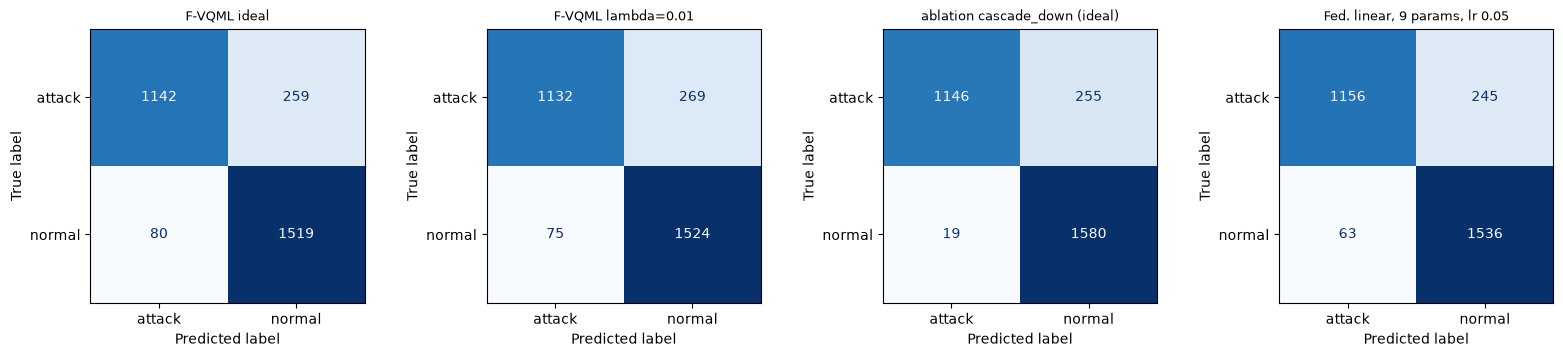

In [25]:
# confusion matrices of the first seed (attack = positive class)
names = ["F-VQML ideal", "F-VQML lambda=0.01", "ablation cascade_down (ideal)", "Fed. linear, 9 params, lr 0.05"]
fig, ax = plt.subplots(1, len(names), figsize=(4 * len(names), 3.6))
for a, k in zip(ax, names):
    run = RESULTS[k][0]
    pred = run["pred_ho"]
    cm = confusion_matrix(y_ho, pred, labels=[1, 0]); ConfusionMatrixDisplay(cm, display_labels=["attack", "normal"]).plot(ax=a, colorbar=False, cmap="Blues")
    a.set_title(k, fontsize=9)
plt.tight_layout(); plt.show()

### Fig. 6: communication payload per node and round
The F-VQML client uploads $\Delta\theta$, 64 floating-point numbers. The classical comparison is the parameter count of the federated MLP above and the raw data of one node's shard.

,values sent,KB/round (float32),KB/round (float64),paper Fig. 6 (KB)
raw shard (centralised),48800.0,190.62,381.25,450
federated MLP (this notebook),24065.0,94.00,188.01,125
F-VQML (64 angles),64.0,0.25,0.50,2


reduction of F-VQML against our federated MLP : 99.7 %   (float32 vs float32)
reduction implied by the paper's own bars     : 98.4 %   (2 KB vs 125 KB)
64 float64 numbers are 0.50 KB, not 2 KB; 2 KB would need 512 float32 numbers.


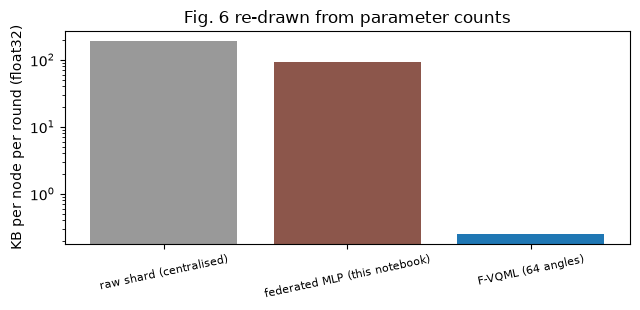

In [26]:
n_q = 64; mlp_params = RESULTS["Fed. MLP (122-128-64-1)"][0]["n_params"]
shard_rows = float(np.mean([len(p) for p in PARTS]))
kb = lambda n_values, b: n_values * b / 1024
payload = pd.DataFrame({
    "values sent": [shard_rows * X_pool.shape[1], mlp_params, n_q],
    "KB/round (float32)": [kb(shard_rows * X_pool.shape[1], 4), kb(mlp_params, 4), kb(n_q, 4)],
    "KB/round (float64)": [kb(shard_rows * X_pool.shape[1], 8), kb(mlp_params, 8), kb(n_q, 8)],
    "paper Fig. 6 (KB)": [450, 125, 2]}, index=["raw shard (centralised)", "federated MLP (this notebook)", "F-VQML (64 angles)"]).round(2)
display(payload)
print(f"reduction of F-VQML against our federated MLP : {100*(1-n_q/mlp_params):.1f} %   (float32 vs float32)")
print(f"reduction implied by the paper's own bars     : {100*(1-2/125):.1f} %   (2 KB vs 125 KB)")
print(f"64 float64 numbers are {n_q*8/1024:.2f} KB, not 2 KB; 2 KB would need 512 float32 numbers.")
fig, ax = plt.subplots(figsize=(6.5, 3.2)); ax.bar(payload.index, payload["KB/round (float32)"], color=["#999", "#8c564b", "#1f77b4"]); ax.set_yscale("log"); ax.set_ylabel("KB per node per round (float32)")
ax.set_title("Fig. 6 re-drawn from parameter counts"); plt.xticks(rotation=12, fontsize=8); plt.tight_layout(); plt.show()

## 7. The noise claims, checked

**(a) Eq. 6.** For a traceless observable the global depolarizing channel scales the expectation by $(1-\lambda)$. We verify it on a random 8-qubit density matrix and compose it over the 64 trainable gates.
**(b) Averaging removes shot noise.** At a fixed parameter vector we estimate one node's gradient from finite-shot circuit runs many times and look at the spread of the *average over N nodes*: it should fall as $1/\sqrt N$ if the shot errors are independent.
**(c) Local noise.** Eq. 4 is a *global* channel; real hardware has local single-qubit noise. We apply a single-qubit depolarizing channel with probability $\lambda$ after every trainable gate, on PennyLane's density-matrix simulator, to the trained ideal model and compare its predictions with the noise-free ones.

In [27]:
# (a) Eq. 6 on a random 8-qubit density matrix
dim = 2 ** N_QUBITS; r1 = np.random.default_rng(11)
M = r1.normal(size=(dim, dim)) + 1j * r1.normal(size=(dim, dim)); rho = M @ M.conj().T; rho /= np.trace(rho).real
Z0 = np.kron(np.diag([1.0, -1.0]), np.eye(dim // 2))
noisy = (1 - LAMBDA) * rho + LAMBDA * np.eye(dim) / dim
print("Tr(Z0 rho_noisy) / Tr(Z0 rho) =", float((np.trace(Z0 @ noisy) / np.trace(Z0 @ rho)).real), " expected 1 - lambda =", 1 - LAMBDA)
print(f"after one channel per trainable gate: (1-lambda)^{N_PARAMS} = {(1-LAMBDA)**N_PARAMS:.3f}")

# (b) spread of the node-averaged shot-noise gradient estimate
gts, P = build_gate_list(N_QUBITS, N_LAYERS, "cascade_up"); rel = relevant_params(gts, P)
th = np.random.default_rng(21).uniform(-np.pi, np.pi, P); idx = np.arange(BATCH)
f0, fp0, fm0 = forward_parameter_shift(A_tr[idx], th, gts, rel); atten = (1 - LAMBDA) ** P
rs = np.random.default_rng(22)
samples = np.array([bce_gradient(*readout(f0, fp0, fm0, atten, SHOTS, rs), y_tr[idx]) for _ in range(NODE_SWEEP_REPS * 10)])
exact = bce_gradient(*readout(f0, fp0, fm0, atten, None, rs), y_tr[idx])
rows = []
for N in (1, 2, 5, 10):
    avg = samples[: (len(samples) // N) * N].reshape(-1, N, P).mean(1)
    rows.append({"nodes averaged N": N, "std of gradient error (rel. to |g|)": float(np.sqrt(((avg - exact) ** 2).sum(1).mean()) / np.linalg.norm(exact))})
sweep = pd.DataFrame(rows); sweep["x sqrt(N)"] = sweep.iloc[:, 1] * np.sqrt(sweep["nodes averaged N"]); display(sweep.round(3))
print("The last column is roughly constant: the error of the averaged gradient falls like 1/sqrt(N), as the paper argues (same data on every node here, so this isolates the shot-noise effect).")

Tr(Z0 rho_noisy) / Tr(Z0 rho) = 0.9900000000000377  expected 1 - lambda = 0.99
after one channel per trainable gate: (1-lambda)^64 = 0.526


,nodes averaged N,std of gradient error (rel. to |g|),x sqrt(N)
0,1,0.107,0.107
1,2,0.076,0.107
2,5,0.048,0.107
3,10,0.034,0.107


The last column is roughly constant: the error of the averaged gradient falls like 1/sqrt(N), as the paper argues (same data on every node here, so this isolates the shot-noise effect).


In [28]:
# (c) local single-qubit depolarizing noise on the trained ideal model (density-matrix simulation)
dev_mixed = qml.device("default.mixed", wires=N_QUBITS)
def make_noisy_qnode(gates, lam):
    @qml.qnode(dev_mixed)
    def circuit(x, theta):
        for kind, q, k in gates:
            if kind == "RYX":  qml.RY(x[q], wires=q)
            elif kind == "RY": qml.RY(theta[k], wires=q); qml.DepolarizingChannel(lam, wires=q)
            elif kind == "RZ": qml.RZ(theta[k], wires=q); qml.DepolarizingChannel(lam, wires=q)
            else:              qml.CNOT(wires=list(q))
        return qml.expval(qml.PauliZ(0))
    return circuit
run0 = RESULTS["F-VQML ideal"][0]; qn_noisy = make_noisy_qnode(run0["gates"], LAMBDA)
sel = np.arange(N_LOCAL_NOISE_EVAL); t0 = time.time()
z_noisy = np.array([float(qn_noisy(A_ho[i], run0["theta"])) for i in sel]); z_ideal = forward(A_ho[sel], run0["theta"], run0["gates"])
print(f"{len(sel)} held-out rows evaluated on default.mixed in {time.time()-t0:.0f}s")
print("mean <Z0> ratio noisy/ideal (local noise):", round(float(np.mean(z_noisy[np.abs(z_ideal) > 0.2] / z_ideal[np.abs(z_ideal) > 0.2])), 3), "(global model of Eq. 4 would give", round((1-LAMBDA)**N_PARAMS, 3), ")")
print("prediction agreement noisy vs ideal:", float(((z_noisy > 0) == (z_ideal > 0)).mean()),
      "| accuracy ideal:", float(((z_ideal > 0).astype(int) == y_ho[sel]).mean()), "| accuracy local-noise:", float(((z_noisy > 0).astype(int) == y_ho[sel]).mean()))

50 held-out rows evaluated on default.mixed in 220s
mean <Z0> ratio noisy/ideal (local noise): 0.872 (global model of Eq. 4 would give 0.526 )
prediction agreement noisy vs ideal: 1.0 | accuracy ideal: 0.76 | accuracy local-noise: 0.76


## 8. Side-by-side with the paper

The table compares the paper's reported numbers with this notebook's final-round numbers (held-out 20 % of `KDDTrain+`, mean over seeds). A claim is **reproduced** when
the notebook is within 2 accuracy points (0.02 for P/R/F1) of the paper, **not reached** when it is lower by more, **exceeded** when it is higher by more, and
**cannot be checked** when the quantity is hardware- or implementation-specific.

In [29]:
def mean_metric(key, metric, split="holdout"):
    return 100 * float(np.mean([r[split][metric] for r in RESULTS[key]]))
def verdict(paper, mine, tol=2.0):
    if abs(mine - paper) <= tol: return "reproduced"
    return "not reached (%.1f pts below)" % (paper - mine) if mine < paper else "exceeded (%.1f pts above)" % (mine - paper)

KI, KN, KL = "F-VQML ideal", "F-VQML lambda=0.01", "Fed. linear, 9 params, lr 0.05"
KL64 = "Fed. linear, 64 params, lr 0.005"; KL64_paper = "Fed. linear, 64 params, lr 0.05"
claims = []
def add(claim, paper, mine, tol=2.0): claims.append((claim, paper, round(mine, 1), verdict(paper, mine, tol)))
add("Ideal F-VQML accuracy (Table IV, round 50)", 94.2, mean_metric(KI, "accuracy"))
add("Ideal macro precision", 92.5, mean_metric(KI, "precision_macro"))
add("Ideal macro recall (the quoted 93.8 %)", 93.8, mean_metric(KI, "recall_macro"))
add("Ideal macro F1", 93.1, mean_metric(KI, "f1_macro"))
add("Noisy (lambda=0.01) accuracy", 89.7, mean_metric(KN, "accuracy"))
add("Noisy macro precision", 86.1, mean_metric(KN, "precision_macro"))
add("Noisy macro recall", 88.4, mean_metric(KN, "recall_macro"))
add("Noisy macro F1", 87.2, mean_metric(KN, "f1_macro"))
add("Classical linear FL accuracy (same 8 inputs, 9 parameters)", 78.1, mean_metric(KL, "accuracy"))
add("Classical linear FL accuracy (64 parameters, stabilised lr 0.005)", 78.1, mean_metric(KL64, "accuracy"))
add("Classical linear FL accuracy (64 parameters, paper lr 0.05, oscillates)", 78.1, mean_metric(KL64_paper, "accuracy"))
add("Peak accuracy of ideal model over the rounds (Fig. 5)", 94.2, 100 * float(np.mean([max(r["acc_hist"]) for r in RESULTS[KI]])))
CLAIMS = pd.DataFrame(claims, columns=["claim", "paper", "this notebook", "verdict"])
display(CLAIMS.style.hide(axis="index"))

gap_p = 94.2 - 89.7; gap_n = mean_metric(KI, "accuracy") - mean_metric(KN, "accuracy")
beats = mean_metric(KI, "accuracy") > mean_metric(KL, "accuracy")
print(f"\nQuantum beats the equal-size linear federated model: paper {94.2-78.1:+.1f} pts, notebook {mean_metric(KI, 'accuracy')-mean_metric(KL, 'accuracy'):+.1f} pts -> {'qualitatively reproduced' if beats else 'not reproduced'}")
print(f"Accuracy cost of depolarizing noise: paper {gap_p:.1f} pts, notebook {gap_n:.1f} pts")
print(f"Ideal accuracy against the stronger classical references (same sample): RF on 8 angles {100*CENTRAL['Random Forest on 8 angles']['holdout']['accuracy']:.1f} %, "
      f"RBF-SVM on 8 angles {100*CENTRAL['SVC (rbf) on 8 angles']['holdout']['accuracy']:.1f} %, RF on 122 features {100*CENTRAL['Random Forest on 122 features']['holdout']['accuracy']:.1f} %.")
print(f"Variance captured by 8 standardised PCs: {100*evr.sum():.1f} % (paper: 'over 94 %'); on un-scaled features {100*raw_pca.explained_variance_ratio_.sum():.1f} %.")
print(f"Upload per node and round: {N_PARAMS} numbers = {N_PARAMS*8/1024:.2f} KB as float64 (paper: 2 KB); saving vs our federated MLP {100*(1-N_PARAMS/mlp_params):.1f} % (paper: 98 %).")
print(f"Trainable parameters that can influence the output: {int(REL.sum())} of {N_PARAMS}; input features that matter: {INFLUENCE[list(ARCHS)[0]]} of 0-7.")
print(f"Wall clock here: ideal run {np.mean([r['time'] for r in RESULTS[KI]]):.0f} s for {ROUNDS} rounds x {N_NODES} nodes x {LOCAL_EPOCHS} steps (paper: ~2.5 min per node and local epoch, 3.2 min per round; not comparable: different simulator/hardware -> cannot be checked).")

claim,paper,this notebook,verdict
"Ideal F-VQML accuracy (Table IV, round 50)",94.200000,90.100000,not reached (4.1 pts below)
Ideal macro precision,92.500000,91.200000,reproduced
Ideal macro recall (the quoted 93.8 %),93.800000,89.600000,not reached (4.2 pts below)
Ideal macro F1,93.100000,89.900000,not reached (3.2 pts below)
Noisy (lambda=0.01) accuracy,89.700000,90.000000,reproduced
Noisy macro precision,86.100000,91.300000,exceeded (5.2 pts above)
Noisy macro recall,88.400000,89.500000,reproduced
Noisy macro F1,87.200000,89.800000,exceeded (2.6 pts above)
"Classical linear FL accuracy (same 8 inputs, 9 parameters)",78.100000,89.600000,exceeded (11.5 pts above)
"Classical linear FL accuracy (64 parameters, stabilised lr 0.005)",78.100000,86.400000,exceeded (8.3 pts above)



Quantum beats the equal-size linear federated model: paper +16.1 pts, notebook +0.5 pts -> qualitatively reproduced
Accuracy cost of depolarizing noise: paper 4.5 pts, notebook 0.1 pts
Ideal accuracy against the stronger classical references (same sample): RF on 8 angles 99.1 %, RBF-SVM on 8 angles 96.1 %, RF on 122 features 99.6 %.
Variance captured by 8 standardised PCs: 26.7 % (paper: 'over 94 %'); on un-scaled features 100.0 %.
Upload per node and round: 64 numbers = 0.50 KB as float64 (paper: 2 KB); saving vs our federated MLP 99.7 % (paper: 98 %).
Trainable parameters that can influence the output: 16 of 64; input features that matter: [0, 1, 2, 3] of 0-7.
Wall clock here: ideal run 446 s for 50 rounds x 10 nodes x 3 steps (paper: ~2.5 min per node and local epoch, 3.2 min per round; not comparable: different simulator/hardware -> cannot be checked).


## 9. Reading the paper critically

* **The circuit as drawn can only see half of the data.** With the nearest-neighbour CNOT cascade run in ascending order and $\langle Z_0\rangle$ as output, qubit 0 only ever acts as a CNOT *control*; information from qubit $j$ reaches it only one qubit per layer. The light-cone check above shows that
  just input features 0-3 and 16 of the 64 parameters can change the prediction (the last $R_z$ layer commutes with the measurement, and so do several others). The headline "64 tunable parameters" is therefore at most 16. Reversing the order of the cascade (ablation) lifts this to 8 features and 42 parameters. Fig. 3 does not reveal which one the authors simulated.
* **PCA arithmetic.** "Eight components capturing over 94 % of the variance" does not hold for standardised NSL-KDD features (one-hot encoded: about a quarter of the variance; it can only hold for un-scaled data, dominated by the byte counters). Which PCA the authors used is not stated.
* **Eq. 3 is applied to the loss.** The parameter-shift rule is exact for the expectation value of a Pauli-rotation circuit, not for a binary cross-entropy of it; the chain rule version used here is the correct one.
* **Noise.** Eq. 4-6 are about a *global* channel, which for a traceless observable merely rescales $\langle Z_0\rangle$ by $(1-\lambda)^{64}$ and never changes the sign of the prediction; a noisy accuracy drop (89.7 % vs 94.2 %) can then only come from slower or noisier optimisation, not from corrupted inference. Real hardware noise is local and also changes the state; the local-noise check above quantifies that for one trained model. "Averaging cancels shot noise" is just the central limit theorem over independent estimates (checked above), and it holds equally for classical federated learning.
* **Baseline.** The "federated linear model restricted to an identical parameter count" is a weak baseline and its details are missing (inputs, learning rate, the 64 parameters). The paper itself concedes in Section VI that Random Forest / XGBoost on the standard KDDTest+ protocol are needed; they are in the table above and reach higher accuracy than the quantum circuit on the same eight inputs.
* **Payload arithmetic.** 64 floats are 0.25-0.5 KB, not 2 KB; the 98 % saving depends on the hand-picked 125 KB MLP.
* **Protocol.** The paper's split, sample size and number of seeds are not given; accuracy depends strongly on them (compare the held-out and `KDDTest+` rows), and a single run has no confidence interval.
* **TON_IoT** is named as necessary future work; nothing in the paper can be checked against it.

## 10. Exercises

1. Set `FAST_MODE = False` and compare the three seeds: how large is the seed-to-seed spread of the final accuracy, and how many rounds does the ideal model need to get within 1 point of its final value?
2. Change `DIRICHLET_ALPHA` to 100 (nearly IID) and to 0.1 (extreme skew). How do the quantum model and the linear baseline react to client drift?
3. Add data re-uploading (repeat the encoding gates before every layer, as the paper suggests in Section VI) in `build_gate_list`. Does the light cone widen? Does accuracy improve?
4. Replace the entangler by a ring (add `CNOT(7, 0)`, so that qubit 0 is also a target) and re-run the light-cone analysis and the training.
5. Repeat the experiment on the TON_IoT network data (Hugging Face `codymlewis/TON_IoT_network`) with the same pipeline: which parts of the paper's story survive a modern IoT dataset?